# EDA

##1.1 데이터 이해 및 구조 파악

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

train = pd.read_csv('/content/drive/MyDrive/[ESAA] OB 1조/프로젝트3/train.csv')

In [4]:
!apt-get update -qq
!apt-get install -y fonts-nanum

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

fm.fontManager.addfont(
    "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
)

plt.rcParams["font.family"] = "NanumGothic"

plt.rcParams["axes.unicode_minus"] = False


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 65 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (44.3 MB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


예측해야할 Target은 (배추, 무, 양파, 사과, 배, 건고추, 깐마늘, 감자, 대파, 상추)의 10개의 품목 중 아래의 특정 품종, 등급에 대해서만 예측을 진행합니다.

##1.2 데이터 전처리 및 품질 검증

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 대회에서 지정한 예측 대상
targets = [
    ("건고추", "화건", "30 kg", "상품"),
    ("사과", "홍로, 후지", "10 개", "상품"),
    ("감자", "감자 수미", "20키로상자", "상"),
    ("배", "신고", "10 개", "상품"),
    ("깐마늘(국산)", "깐마늘(국산)", "20 kg", "상품"),
    ("무", "무", "20키로상자", "상"),
    ("상추", "청", "100 g", "상품"),
    ("배추", "배추", "10키로망대", "상"),
    ("양파", "양파", "1키로", "상"),
    ("대파", "대파(일반)", "1키로단", "상")
]

# 문자열 공백 정리
for col in ["품목명", "품종명", "거래단위", "등급"]:
    train[col] = train[col].astype(str).str.strip()

# 대상 필터링
mask = pd.Series(False, index=train.index)

for item, variety, unit, grade in targets:
    condition = (
        (train["품목명"] == item) &
        (train["품종명"] == variety) &
        (train["거래단위"] == unit) &
        (train["등급"] == grade)
    )
    mask |= condition

target_df = train[mask].copy()

# 시점 순서 생성
target_df["year"] = target_df["시점"].str[:4].astype(int)
target_df["month"] = target_df["시점"].str[4:6].astype(int)
target_df["soon"] = target_df["시점"].str[-2:].map(
    {"상순": 1, "중순": 2, "하순": 3}
)
target_df["time_index"] = (
    (target_df["year"] - 2018) * 36 +
    (target_df["month"] - 1) * 3 +
    target_df["soon"]
)

# 품목별 데이터 개수 및 0원 확인
print(target_df.groupby("품목명")["평균가격(원)"].agg(
    count="count",
    mean="mean",
    std="std",
    min="min",
    max="max"
))

print("\n품목별 0원 개수")
print(target_df.groupby("품목명")["평균가격(원)"].apply(
    lambda x: (x == 0).sum()
))


# 월별 계절성
seasonality = target_df.groupby(
    ["품목명", "month"]
)["평균가격(원)"].mean().unstack()

print("\n월별 평균가격")
display(seasonality)


         count           mean            std            min            max
품목명                                                                       
감자         144   36446.472495   16835.695830   16343.600000  115127.750000
건고추        144  597980.802083  130256.492058  396000.000000  905650.000000
깐마늘(국산)    144  122036.210648   27518.051370   74500.000000  169100.000000
대파         144    1785.862114     946.891808     698.444444    5488.833333
무          144   12669.117664    5536.419223    5724.444444   27820.600000
배          144   36352.687500    6741.386965   26699.000000   53463.000000
배추         144    7847.127714    4118.276746    2466.111111   25820.875000
상추         144    1062.298611     394.579870     623.000000    2403.000000
양파         144     865.948851     332.813123     389.888889    2021.166667

품목별 0원 개수
품목명
감자         0
건고추        0
깐마늘(국산)    0
대파         0
무          0
배          0
배추         0
상추         0
양파         0
Name: 평균가격(원), dtype: int64

월별 평균가격


month,1,2,3,4,5,6,7,8,9,10,11,12
품목명,,,,,,,,,,,,
감자,39040.016700,45132.427282,55232.290972,62866.484954,41355.042361,21939.447917,21674.207639,28754.084193,30024.349173,28378.165278,31003.416667,31957.736806
건고추,587930.916667,584517.333333,581393.583333,581314.250000,580834.916667,594253.166667,595623.666667,606804.458333,656052.250000,606295.750000,601671.666667,599077.666667
깐마늘(국산),116681.638889,118368.916667,119451.916667,121771.333333,122799.416667,117979.895833,118547.493056,124937.500000,123625.166667,124394.166667,127725.291667,128151.791667
대파,1826.575529,2184.203638,1890.404398,1709.841435,1630.367361,1322.460648,1359.151852,1918.726025,2175.243882,1994.802083,1865.197917,1553.370602
무,12878.799901,11563.286078,11386.327778,11638.232639,11766.020602,10296.234954,11353.970602,15100.603009,16677.479001,14136.343981,11655.241898,13576.871528
배,35179.833333,36577.416667,36411.833333,36559.750000,36922.916667,37898.750000,40004.166667,40299.750000,34182.166667,34099.083333,33281.916667,34814.666667
배추,5530.396925,6936.073446,7047.467824,7011.020833,5923.190741,5659.969907,7470.713194,11746.925694,14628.733730,8761.489352,7439.334491,6010.216435
상추,1045.500000,955.416667,760.166667,749.250000,769.333333,835.583333,1099.833333,1623.333333,1749.333333,1316.500000,978.500000,864.833333
양파,1069.369940,1176.998611,1083.013889,921.386574,653.909491,619.657407,657.947454,807.297718,811.034292,839.840741,871.075231,879.854861


사과데이터가 누락 됨

In [6]:

# 사과 데이터의 품종 및 거래단위 확인
apple = train[train["품목명"] == "사과"]

print("품종명:", apple["품종명"].unique())
print("거래단위:", apple["거래단위"].unique())
print("등급:", apple["등급"].unique())

display(
    apple[["시점", "품종명", "거래단위", "등급", "평균가격(원)"]].head(15)
)

품종명: ['후지' '홍로' '쓰가루']
거래단위: ['10 개']
등급: ['상품' '중품']


,시점,품종명,거래단위,등급,평균가격(원)
1152,201801상순,후지,10 개,상품,20361.0
1153,201801중순,후지,10 개,상품,20359.0
1154,201801하순,후지,10 개,상품,20653.0
1155,201802상순,후지,10 개,상품,20563.0
1156,201802중순,후지,10 개,상품,21779.0
1157,201802하순,후지,10 개,상품,21465.0
1158,201803상순,후지,10 개,상품,21384.0
1159,201803중순,후지,10 개,상품,20695.0
1160,201803하순,후지,10 개,상품,20794.0
1161,201804상순,후지,10 개,상품,19019.0


In [7]:

# 사과 중 홍로, 후지만 추출
apple_target = train[
    (train["품목명"] == "사과") &
    (train["품종명"].isin(["홍로", "후지"])) &
    (train["거래단위"] == "10 개") &
    (train["등급"] == "상품")
].copy()

# 품종별 데이터 확인
print(apple_target.groupby("품종명").size())

# 시점별 사과 품종 가격 확인
apple_pivot = apple_target.pivot_table(
    index="시점",
    columns="품종명",
    values="평균가격(원)",
    aggfunc="mean"
)

display(apple_pivot.head(10))

품종명
홍로     19
후지    125
dtype: int64


품종명,홍로,후지
시점,,
201801상순,NaN,20361.0
201801중순,NaN,20359.0
201801하순,NaN,20653.0
201802상순,NaN,20563.0
201802중순,NaN,21779.0
201802하순,NaN,21465.0
201803상순,NaN,21384.0
201803중순,NaN,20695.0
201803하순,NaN,20794.0


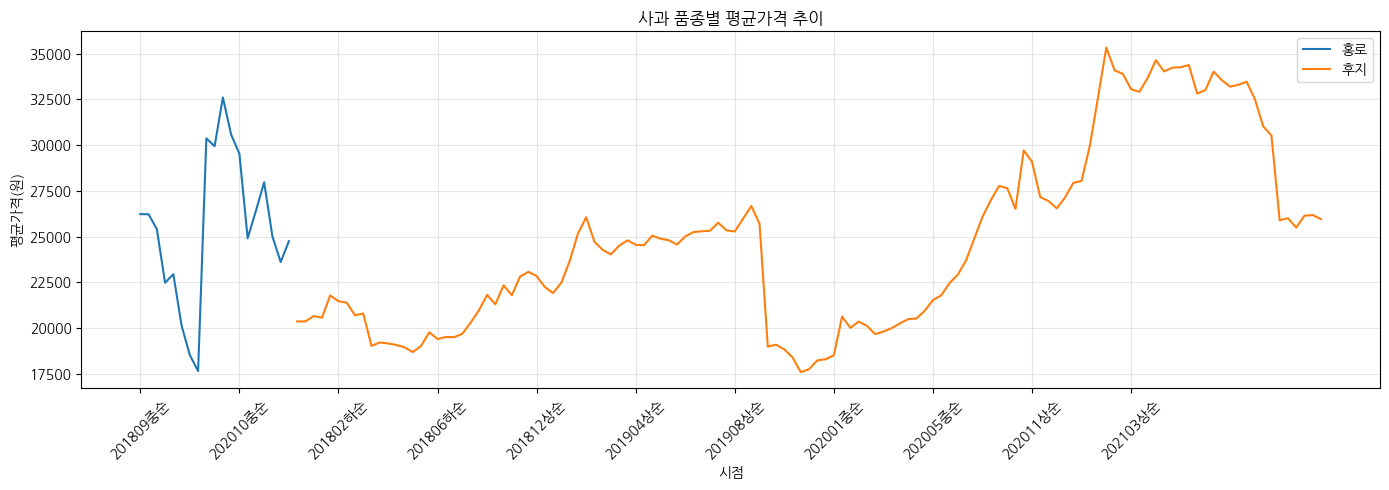

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

for variety in ["홍로", "후지"]:
    subset = apple_target[
        apple_target["품종명"] == variety
    ].sort_values("시점")

    plt.plot(
        subset["시점"],
        subset["평균가격(원)"],
        label=variety
    )

plt.title("사과 품종별 평균가격 추이")
plt.xlabel("시점")
plt.ylabel("평균가격(원)")
plt.legend()
plt.xticks(
    ticks=range(0, len(subset), 12),
    rotation=45
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

전체 행 수: 144
고유 시점 수: 144

중복 시점:
Empty DataFrame
Columns: [시점, 품종명, 평균가격(원)]
Index: []


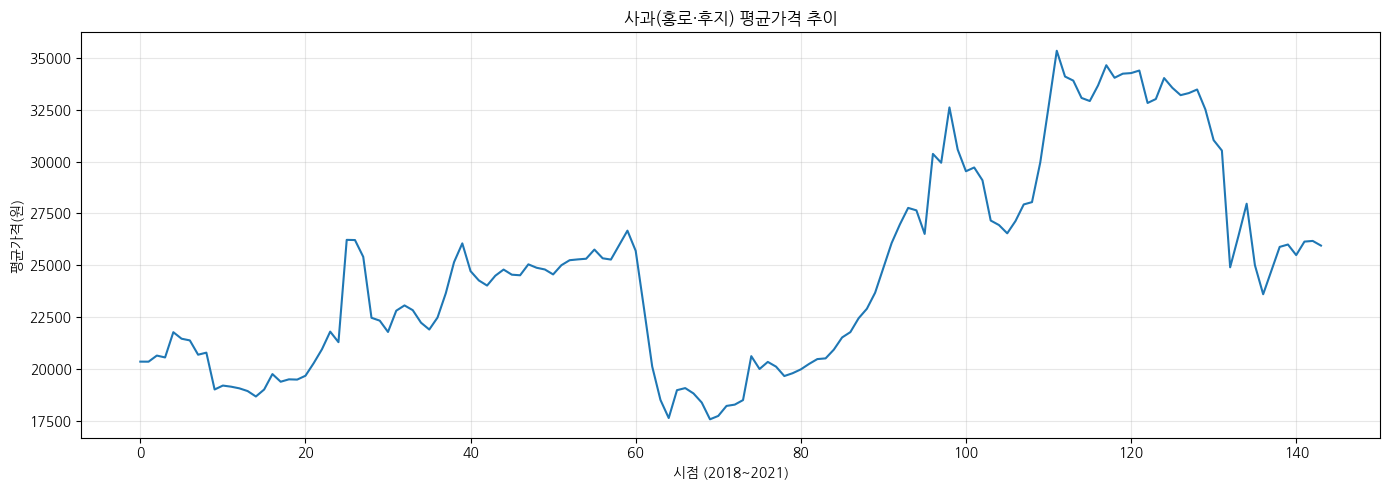

In [9]:

# 사과 품종별 데이터를 시점 순으로 정리
apple_series = apple_target.sort_values("시점").copy()

# 시점별 데이터 개수 확인
print("전체 행 수:", len(apple_series))
print("고유 시점 수:", apple_series["시점"].nunique())

# 동일 시점에 여러 품종이 있는지 확인
print("\n중복 시점:")
print(
    apple_series[
        apple_series.duplicated("시점", keep=False)
    ][["시점", "품종명", "평균가격(원)"]]
)

# 사과 시계열 시각화
plt.figure(figsize=(14, 5))

plt.plot(
    range(len(apple_series)),
    apple_series["평균가격(원)"],
    color="tab:blue"
)

plt.title("사과(홍로·후지) 평균가격 추이")
plt.xlabel("시점 (2018~2021)")
plt.ylabel("평균가격(원)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

# 사과 데이터에 시계열 변수 추가
apple_series["year"] = apple_series["시점"].str[:4].astype(int)
apple_series["month"] = apple_series["시점"].str[4:6].astype(int)
apple_series["soon"] = apple_series["시점"].str[-2:].map(
    {"상순": 1, "중순": 2, "하순": 3}
)

apple_series["time_index"] = (
    (apple_series["year"] - 2018) * 36 +
    (apple_series["month"] - 1) * 3 +
    apple_series["soon"]
)

# 기존 데이터에 사과 추가
target_df = pd.concat(
    [target_df, apple_series],
    ignore_index=True
)

# 품목별 시점 개수 확인
print(target_df.groupby("품목명")["시점"].nunique())

# 전체 품목 수 확인
print("전체 품목 수:", target_df["품목명"].nunique())


품목명
감자         144
건고추        144
깐마늘(국산)    144
대파         144
무          144
배          144
배추         144
사과         144
상추         144
양파         144
Name: 시점, dtype: int64
전체 품목 수: 10


사과의 경우 예측 대상인 홍로와 후지가 서로 다른 시점에 관측되는 특징을 보였다. 홍로는 전체 144개 순 중 19개, 후지는 125개 순에서 관측되었다. 따라서 사과 가격 예측에서는 가격 변화뿐 아니라 품종 전환에 따른 가격 수준의 차이도 고려할 필요가 있다.

In [11]:
print("전체 행 수:", len(target_df))

print("\n컬럼별 결측치:")
print(target_df.isnull().sum())

duplicate_count = target_df.duplicated(
    subset=["품목명", "시점"]
).sum()
print("\n중복 시점 개수:", duplicate_count)

expected_times = set(train["시점"].unique())

for item, group in target_df.groupby("품목명"):
    missing_times = expected_times - set(group["시점"])

    print(f"{item}: 누락 시점 {len(missing_times)}개")

print("\n가격 0원 개수:",
      (target_df["평균가격(원)"] == 0).sum())

전체 행 수: 1440

컬럼별 결측치:
시점            0
품목명           0
품종명           0
거래단위          0
등급            0
평년 평균가격(원)    0
평균가격(원)       0
year          0
month         0
soon          0
time_index    0
dtype: int64

중복 시점 개수: 0
감자: 누락 시점 0개
건고추: 누락 시점 0개
깐마늘(국산): 누락 시점 0개
대파: 누락 시점 0개
무: 누락 시점 0개
배: 누락 시점 0개
배추: 누락 시점 0개
사과: 누락 시점 0개
상추: 누락 시점 0개
양파: 누락 시점 0개

가격 0원 개수: 0


2018년부터 2021년까지의 농산물 가격 데이터에서 예측 대상인 10개 품목의 품종, 등급 및 거래단위를 기준으로 데이터를 추출하였다.

사과는 홍로와 후지가 서로 다른 시점에 관측되는 특성을 고려하여 하나의 연속된 시계열로 통합하였다.

최종적으로 총 1,440개의 관측치를 확보하였으며, 품목별로 144개의 순별 데이터가 존재함을 확인하였다.

##1.3 품목별 가격 특성 분석
농산물별 평균가격, 표준편차, 최솟값, 최댓값을 계산하여 품목 간 가격 수준과 변동 특성을 비교한다.

In [12]:

price_stats = target_df.groupby("품목명")["평균가격(원)"].agg(
    평균가격="mean",
    표준편차="std",
    최솟값="min",
    최댓값="max"
)

# 변동계수(CV) 계산
price_stats["변동계수(%)"] = (
    price_stats["표준편차"] / price_stats["평균가격"] * 100
)

# 가격 범위 계산
price_stats["가격범위"] = (
    price_stats["최댓값"] - price_stats["최솟값"]
)

price_stats = price_stats.sort_values(
    "변동계수(%)", ascending=False
)

display(price_stats.round(2))


,평균가격,표준편차,최솟값,최댓값,변동계수(%),가격범위
품목명,,,,,,
대파,1785.86,946.89,698.44,5488.83,53.02,4790.39
배추,7847.13,4118.28,2466.11,25820.88,52.48,23354.76
감자,36446.47,16835.70,16343.60,115127.75,46.19,98784.15
무,12669.12,5536.42,5724.44,27820.60,43.70,22096.16
양파,865.95,332.81,389.89,2021.17,38.43,1631.28
상추,1062.30,394.58,623.00,2403.00,37.14,1780.00
깐마늘(국산),122036.21,27518.05,74500.00,169100.00,22.55,94600.00
건고추,597980.80,130256.49,396000.00,905650.00,21.78,509650.00
사과,24809.94,4848.51,17583.00,35339.00,19.54,17756.00


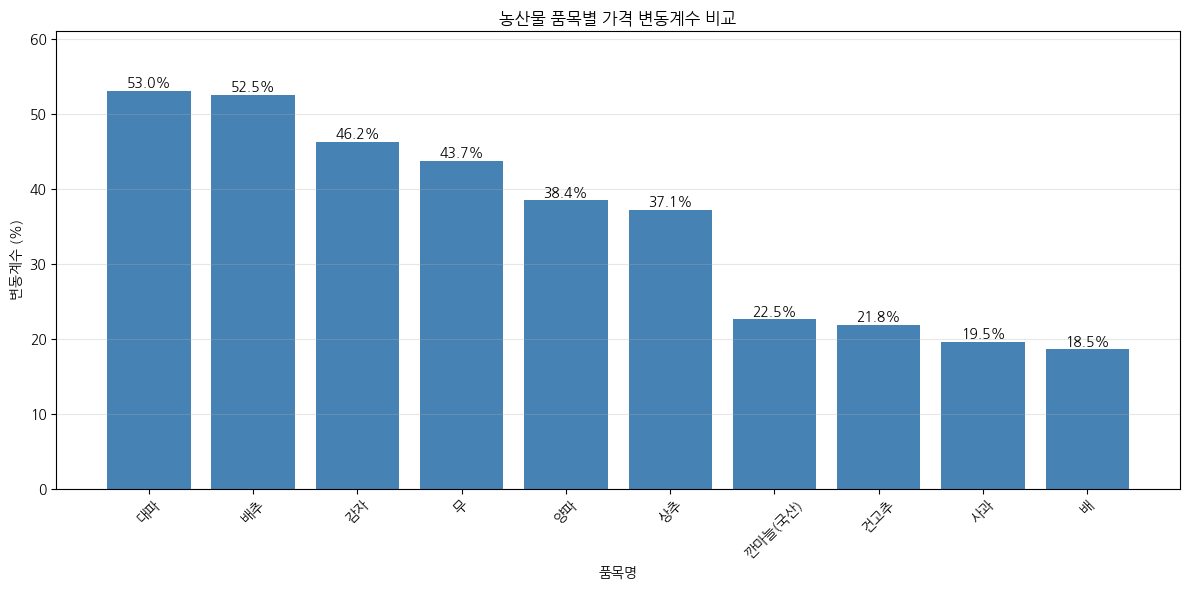

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

bars = plt.bar(
    price_stats.index,
    price_stats["변동계수(%)"],
    color="steelblue"
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.1f}%",
        ha="center",
        fontsize=10
    )

plt.title("농산물 품목별 가격 변동계수 비교")
plt.xlabel("품목명")
plt.ylabel("변동계수 (%)")
plt.xticks(rotation=45)
plt.ylim(0, price_stats["변동계수(%)"].max() * 1.15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

10개 농산물의 평균가격, 표준편차, 최솟값, 최댓값 및 변동계수(CV)를 산출하여 품목별 가격 특성을 비교하였다.

분석 결과, 대파(53.02%), 배추(52.48%), 감자(46.19%) 순으로 변동계수가 높게 나타났으며, 배(18.54%)와 사과(19.54%)는 상대적으로 낮은 변동성을 보였다.

특히 건고추는 평균가격이 가장 높았으나 변동계수는 21.78%로 비교적 낮았다. 이를 통해 농산물의 절대적인 가격 수준과 상대적 가격 변동성은 반드시 일치하지 않음을 확인하였다.

이러한 결과는 농산물별 가격 변동 특성에 차이가 있음을 보여주며, 향후 가격 예측 모델 구축 시 품목별 특성을 고려할 필요가 있음을 시사한다.

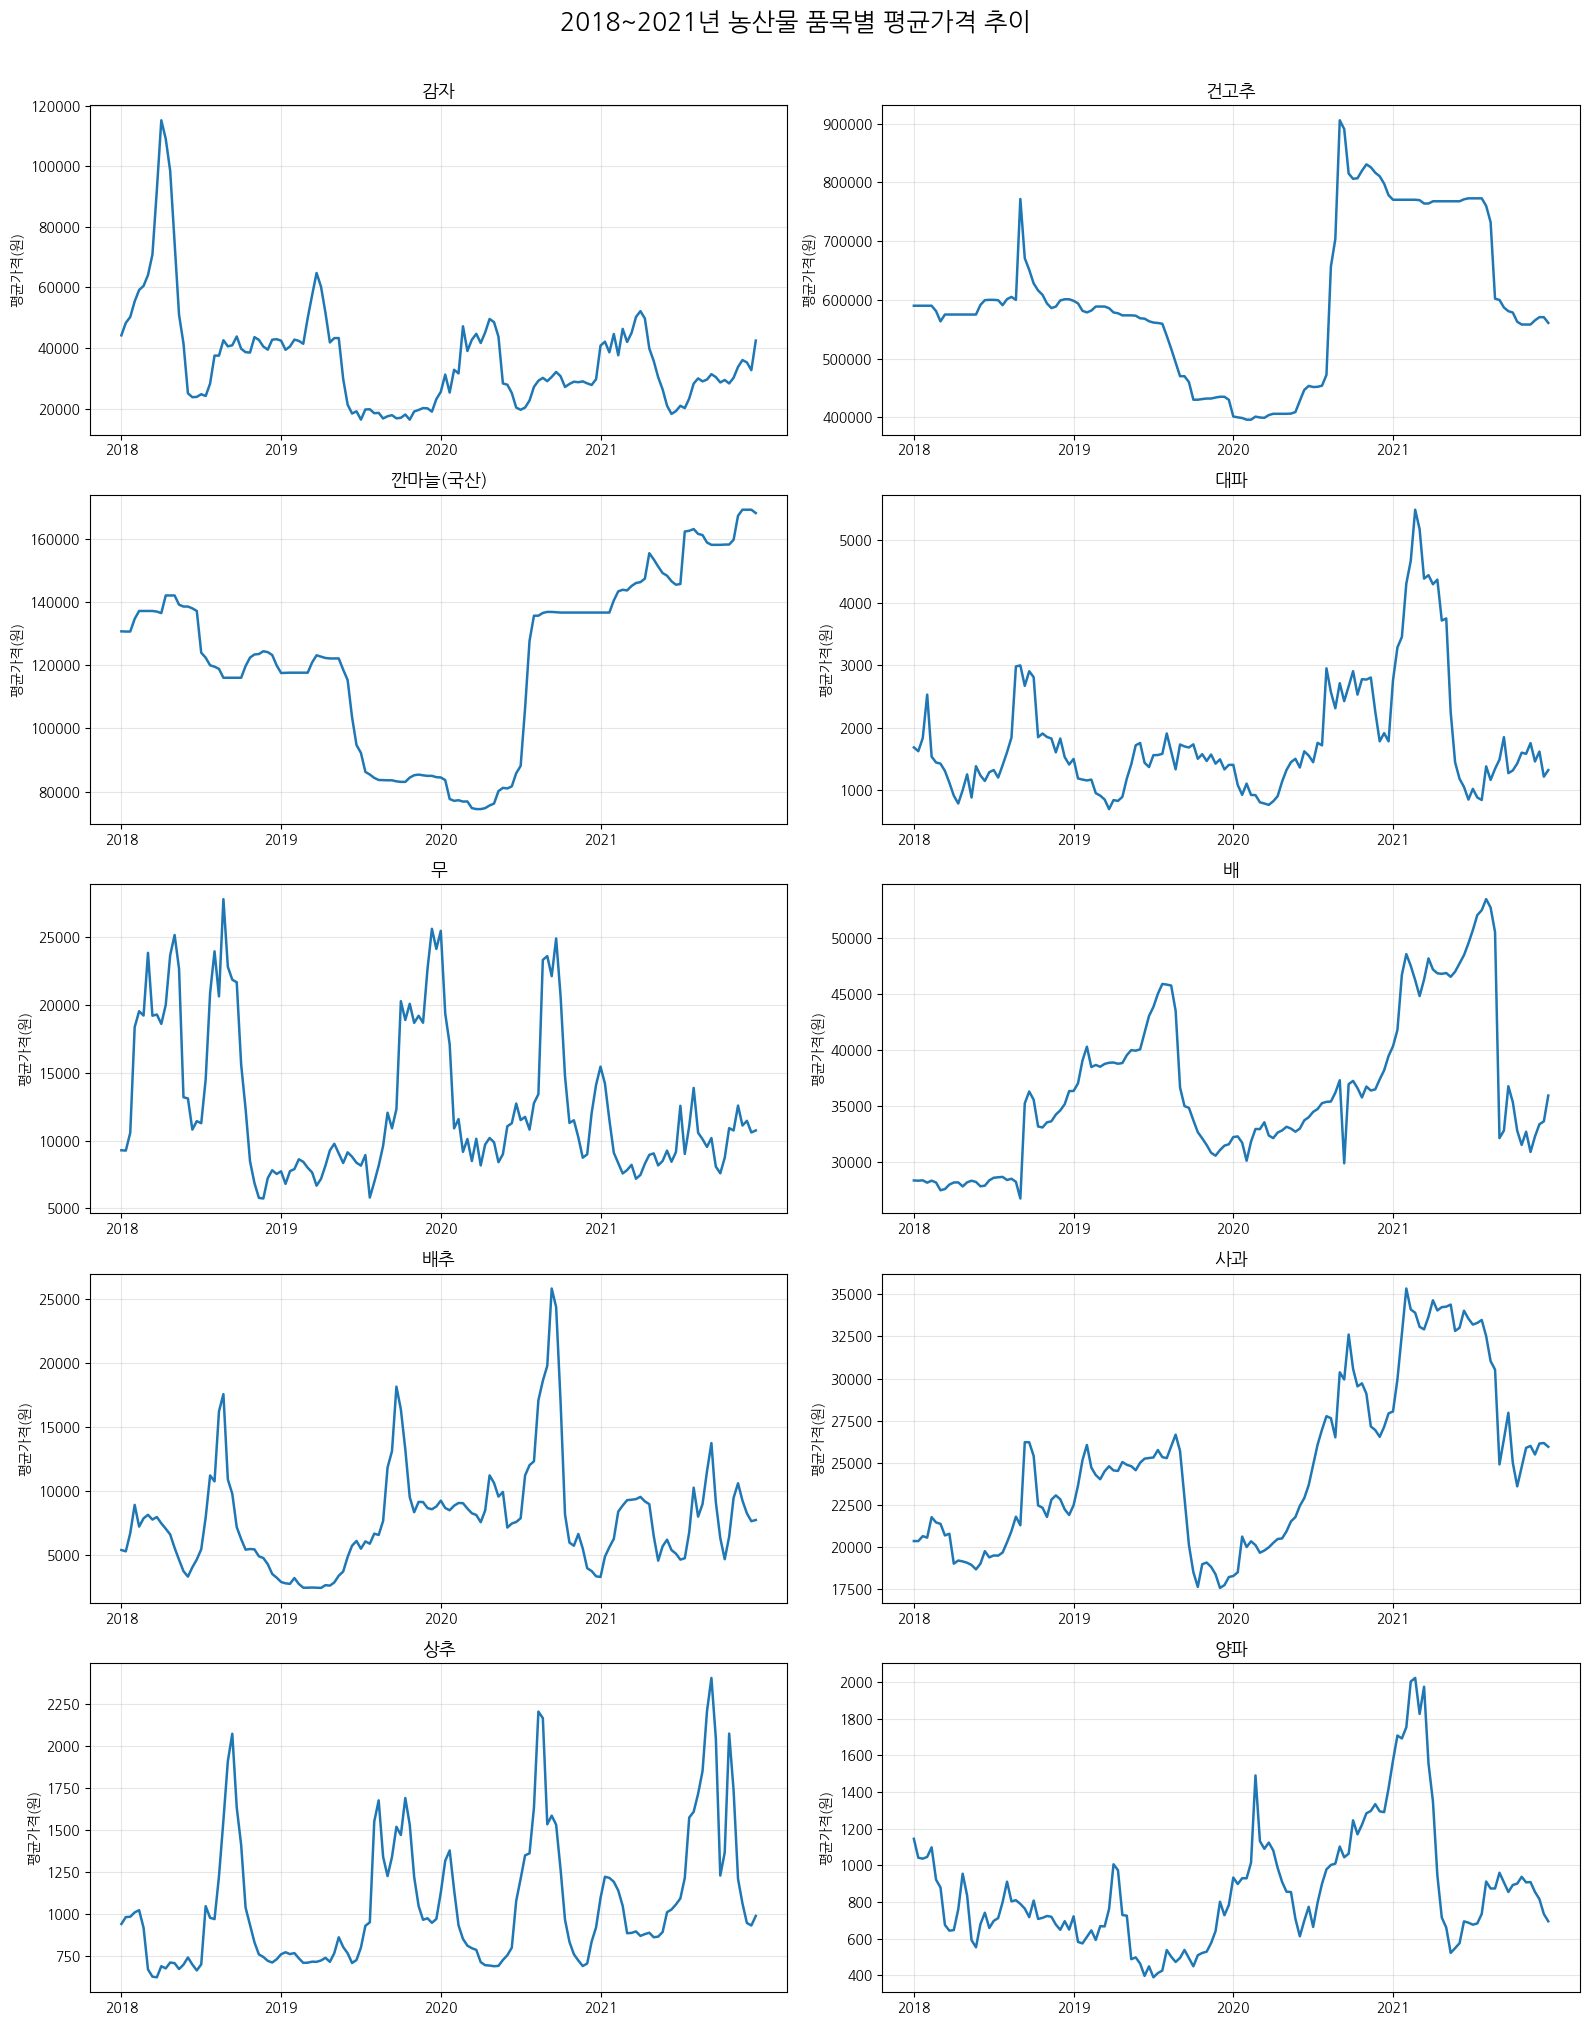

In [14]:
import matplotlib.pyplot as plt

items = sorted(target_df["품목명"].unique())

fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for ax, item in zip(axes, items):

    data = target_df[
        target_df["품목명"] == item
    ].sort_values("time_index")

    ax.plot(
        data["time_index"],
        data["평균가격(원)"],
        linewidth=1.8
    )

    ax.set_title(item, fontsize=13)
    ax.set_ylabel("평균가격(원)")

    # 연도별 x축 표시
    ax.set_xticks([1, 37, 73, 109])
    ax.set_xticklabels(["2018", "2019", "2020", "2021"])

    ax.grid(alpha=0.3)

plt.suptitle(
    "2018~2021년 농산물 품목별 평균가격 추이",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()


2018년부터 2021년까지 10개 농산물의 순별 평균가격 추이를 시각화하여 품목별 가격 변동 패턴을 비교하였다.

분석 결과, 대파·배추·무·상추는 특정 시점에 가격이 급격하게 상승하거나 하락하는 특징을 보였다. 특히 대파는 2021년 초 약 5,500원까지 상승한 이후 빠르게 하락하였으며, 배추는 여러 연도에서 급격한 가격 상승 구간이 관찰되었다.

반면 건고추·깐마늘·사과·배는 상대적으로 장기간에 걸친 가격 수준의 변화가 두드러졌다. 특히 건고추와 깐마늘은 2020년 후반 이후 가격이 크게 상승하는 양상을 보였다.

감자와 양파는 분석 기간 동안 여러 차례 상승과 하락을 반복하는 모습을 나타냈다.

이러한 결과는 농산물별로 가격 변동의 크기뿐 아니라 변화 양상에도 차이가 존재함을 보여준다. 따라서 향후 가격 예측에서는 품목별 가격 추세, 최근 변화율 및 시차 정보를 함께 고려할 필요가 있다

In [15]:
# 기존 데이터에서 사과를 제외
base_df = target_df[
    target_df["품목명"] != "사과"
].copy()

# 원본 데이터에서 사과(홍로, 후지) 다시 추출
apple_final = train[
    (train["품목명"] == "사과") &
    (train["품종명"].isin(["홍로", "후지"])) &
    (train["거래단위"] == "10 개") &
    (train["등급"] == "상품")
].copy()

# 사과 시계열 변수 생성
apple_final["year"] = apple_final["시점"].str[:4].astype(int)
apple_final["month"] = apple_final["시점"].str[4:6].astype(int)
apple_final["soon"] = apple_final["시점"].str[-2:].map(
    {"상순": 1, "중순": 2, "하순": 3}
)

apple_final["time_index"] = (
    (apple_final["year"] - 2018) * 36 +
    (apple_final["month"] - 1) * 3 +
    apple_final["soon"]
)

# 기존 9개 품목 + 사과 통합
target_df = pd.concat(
    [base_df, apple_final],
    ignore_index=True
)

# 품목, 시점 순서대로 정렬
target_df = target_df.sort_values(
    ["품목명", "time_index"]
).reset_index(drop=True)

# 최종 검증
print("전체 품목 수:", target_df["품목명"].nunique())
print("전체 데이터 수:", len(target_df))
print(target_df.groupby("품목명")["시점"].nunique())

# 오류가 있으면 분석 중단
assert target_df["품목명"].nunique() == 10
assert len(target_df) == 1440
assert target_df.groupby("품목명")["시점"].nunique().eq(144).all()
assert not target_df.duplicated(["품목명", "시점"]).any()

print("\n10개 품목 데이터 구성 완료!")


전체 품목 수: 10
전체 데이터 수: 1440
품목명
감자         144
건고추        144
깐마늘(국산)    144
대파         144
무          144
배          144
배추         144
사과         144
상추         144
양파         144
Name: 시점, dtype: int64

10개 품목 데이터 구성 완료!


year,2018,2019,2020,2021
품목명,,,,
감자,46.14,49.47,25.77,27.08
건고추,6.04,12.37,34.48,13.66
깐마늘(국산),7.07,17.05,27.13,6.46
대파,36.04,22.99,41.83,61.43
무,40.94,49.23,38.68,20.45
배,10.36,12.18,6.78,17.40
배추,45.79,64.30,51.57,30.22
사과,9.22,13.05,17.06,12.43
상추,38.04,32.24,38.28,34.05


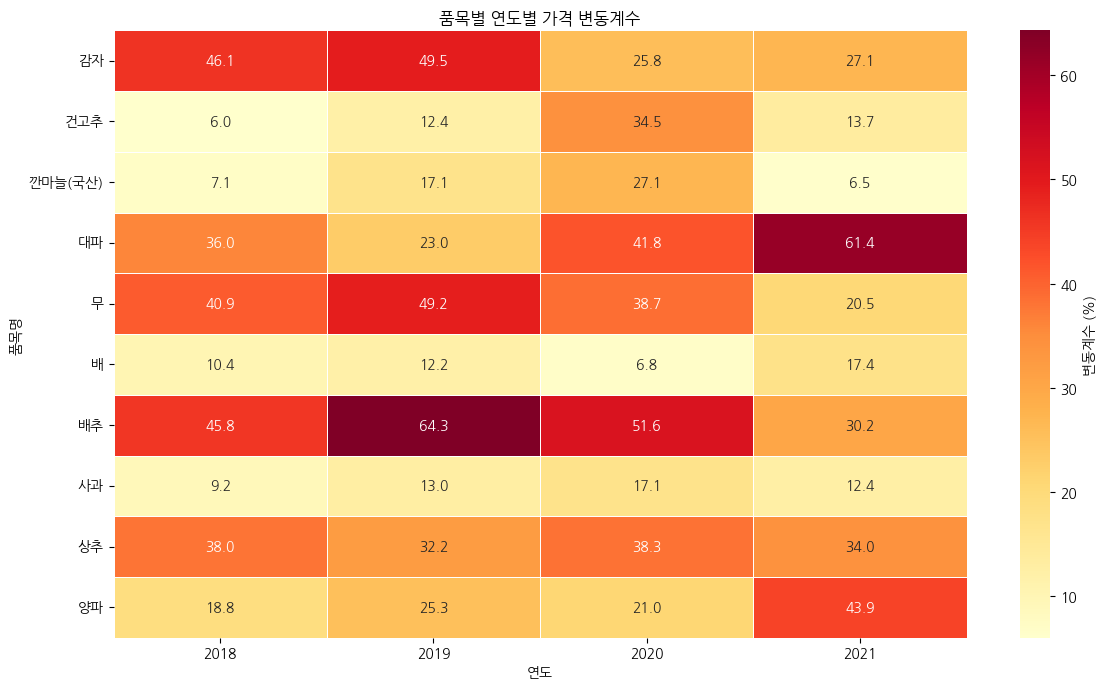

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

yearly_stats = target_df.groupby(
    ["품목명", "year"]
)["평균가격(원)"].agg(["mean", "std"])

yearly_stats["CV"] = (
    yearly_stats["std"] / yearly_stats["mean"] * 100
)

yearly_cv = yearly_stats["CV"].unstack()

display(yearly_cv.round(2))

plt.figure(figsize=(12, 7))

sns.heatmap(
    yearly_cv,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "변동계수 (%)"}
)

plt.title("품목별 연도별 가격 변동계수")
plt.xlabel("연도")
plt.ylabel("품목명")
plt.tight_layout()
plt.show()


- 대파는 2021년에 변동계수가 61.4%로 크게 증가
- 배추는 2019년 64.3%로 특히 높은 변동성을 보임 2020년에도 51.6%로 높았음
- 사과와 배는 대부분의 연도에서 상대적으로 낮은 변동성을 유지

즉, 품목별 변동성뿐 아니라 같은 품목 내에서도 연도에 따라 변동성이 크게 달라질 수 있다는 점을 확인

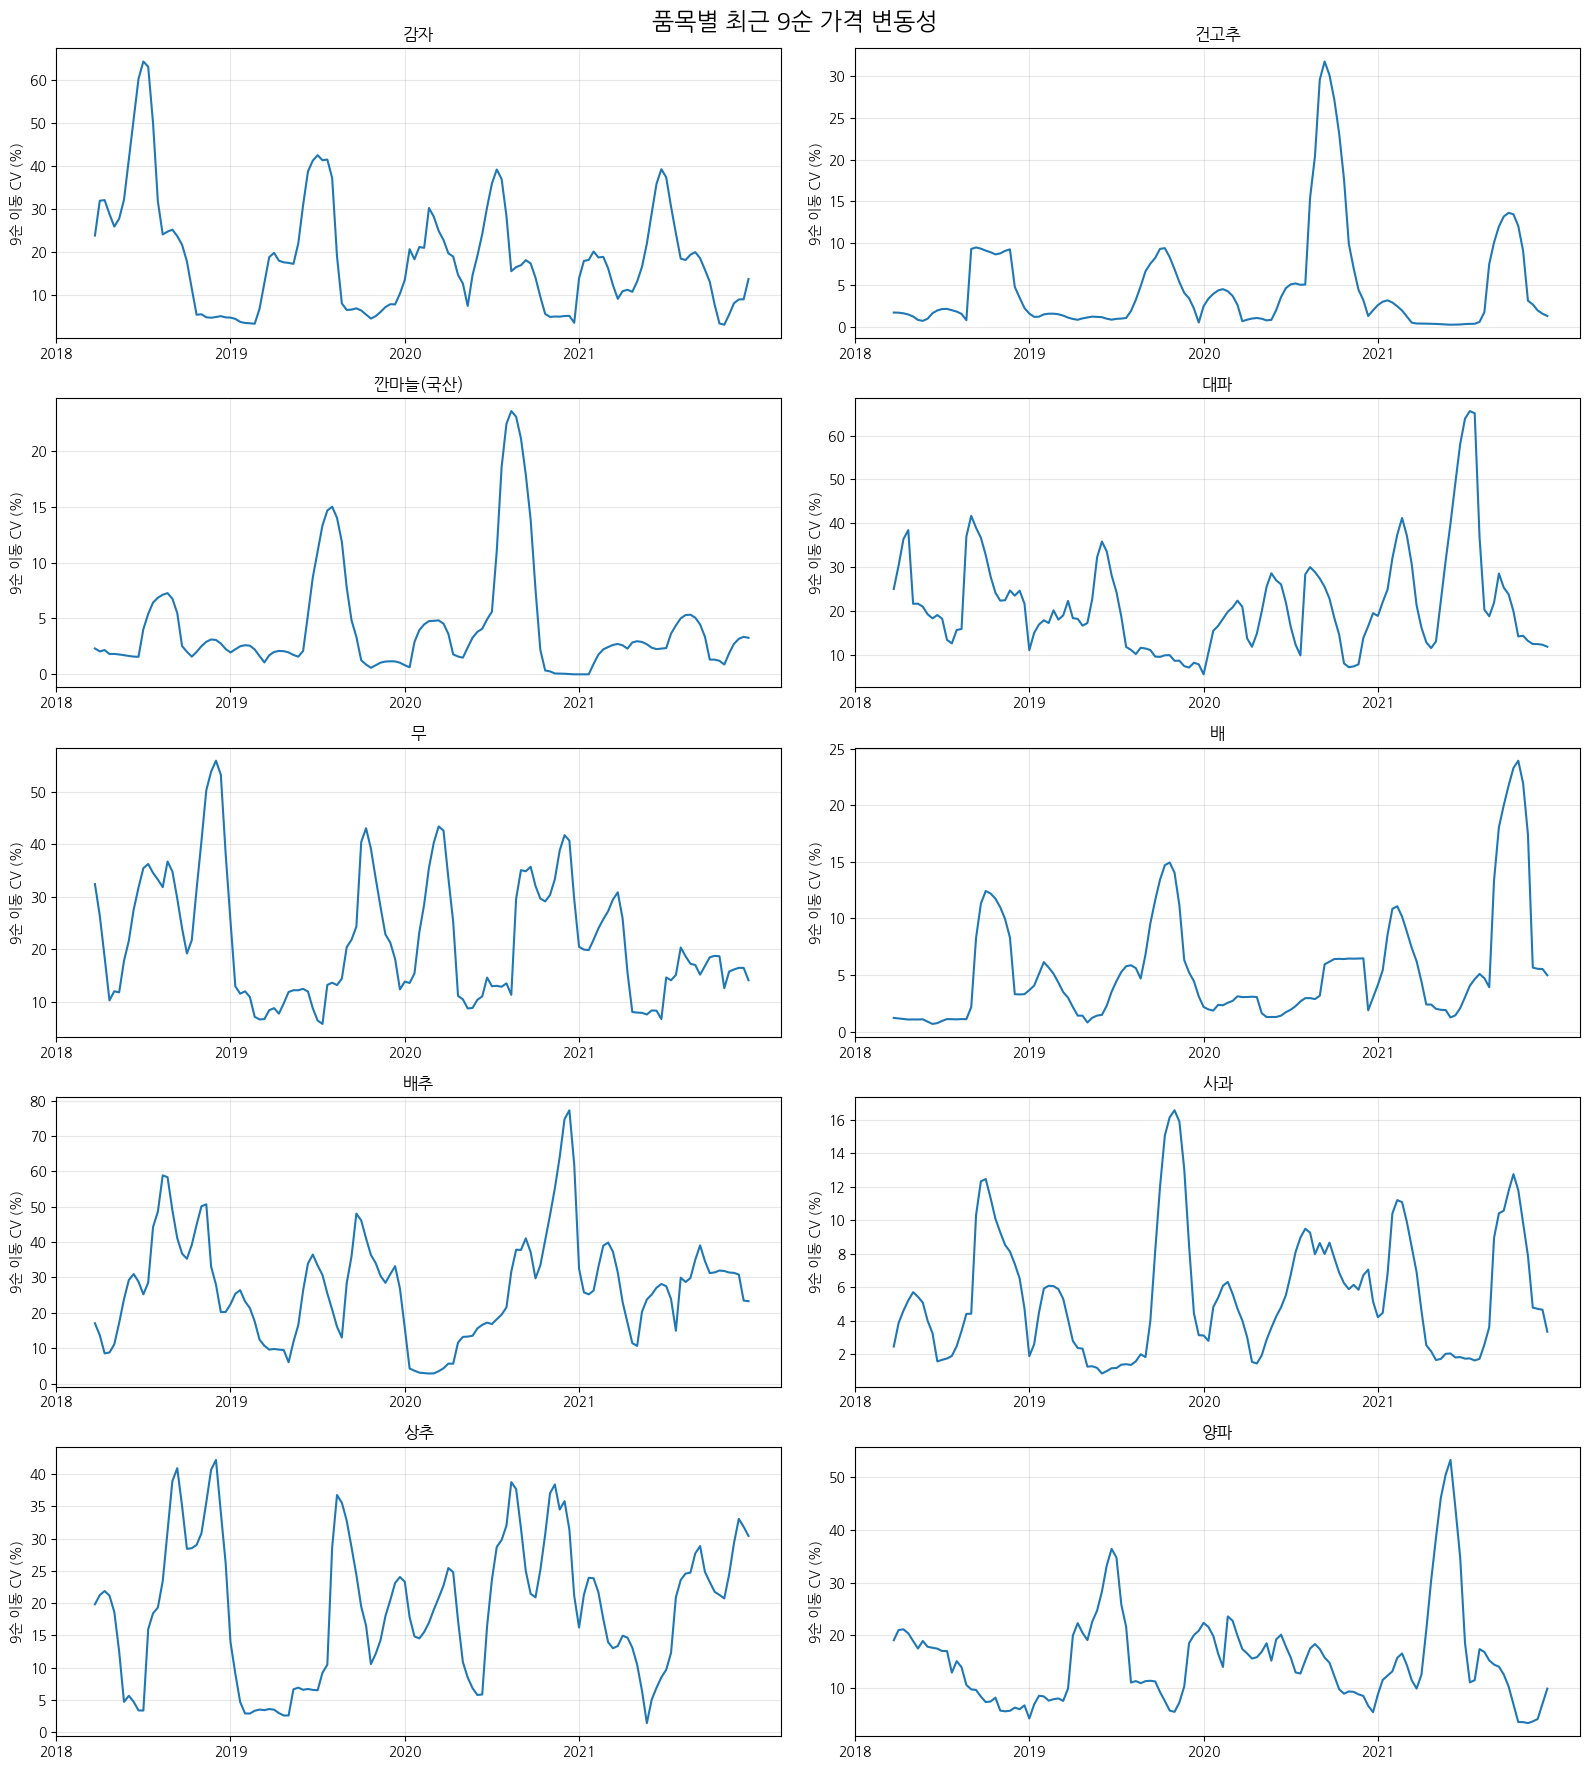

In [17]:
rolling_df = target_df.sort_values(
    ["품목명", "time_index"]
).copy()

# 최근 9순 이동평균
rolling_df["rolling_mean_9"] = (
    rolling_df.groupby("품목명")["평균가격(원)"]
    .transform(lambda x: x.rolling(9).mean())
)

# 최근 9순 이동표준편차
rolling_df["rolling_std_9"] = (
    rolling_df.groupby("품목명")["평균가격(원)"]
    .transform(lambda x: x.rolling(9).std())
)

# 이동 변동계수
rolling_df["rolling_cv_9"] = (
    rolling_df["rolling_std_9"] /
    rolling_df["rolling_mean_9"] * 100
)

# 시각화
fig, axes = plt.subplots(5, 2, figsize=(16, 18))
axes = axes.flatten()

for ax, (item, group) in zip(
    axes, rolling_df.groupby("품목명")
):
    ax.plot(
        group["time_index"],
        group["rolling_cv_9"]
    )

    ax.set_title(item)
    ax.set_ylabel("9순 이동 CV (%)")
    ax.set_xticks([1, 37, 73, 109])
    ax.set_xticklabels(["2018", "2019", "2020", "2021"])
    ax.grid(alpha=0.3)

plt.suptitle("품목별 최근 9순 가격 변동성", fontsize=17)
plt.tight_layout()
plt.show()

실제로 가격이 얼마나 급격히 변했는지 분석

전체 기간의 변동계수는 가격의 전반적인 변동성을 보여주지만 직전 순 대비 가격 변화율을 계산하면 단기간 급등과 급락을 더 구체적으로 확인가능

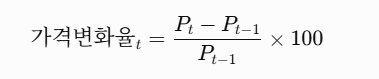

In [18]:

change_df = target_df.sort_values(
    ["품목명", "time_index"]
).copy()

change_df["가격변화율(%)"] = (
    change_df.groupby("품목명")["평균가격(원)"]
    .pct_change(fill_method=None) * 100
)

# 품목별 변화율 통계
change_stats = change_df.groupby("품목명")[
    "가격변화율(%)"
].agg(
    평균변화율="mean",
    변화율표준편차="std",
    최대상승률="max",
    최대하락률="min"
)

display(change_stats.round(2))

,평균변화율,변화율표준편차,최대상승률,최대하락률
품목명,,,,
감자,0.92,13.74,49.18,-39.61
건고추,0.09,5.40,39.04,-17.79
깐마늘(국산),0.23,3.38,20.73,-10.20
대파,1.48,18.85,71.73,-40.00
무,1.71,18.59,73.87,-41.79
배,0.34,5.72,31.86,-36.45
배추,2.10,19.60,54.11,-51.70
사과,0.28,4.68,23.14,-18.42
상추,1.02,14.43,63.05,-39.89


,급등횟수,급락횟수,총급변동횟수
품목명,,,
배추,21,14,35
무,16,14,30
대파,18,10,28
감자,13,7,20
상추,9,9,18
양파,8,9,17
건고추,3,0,3
배,2,1,3
깐마늘(국산),1,0,1


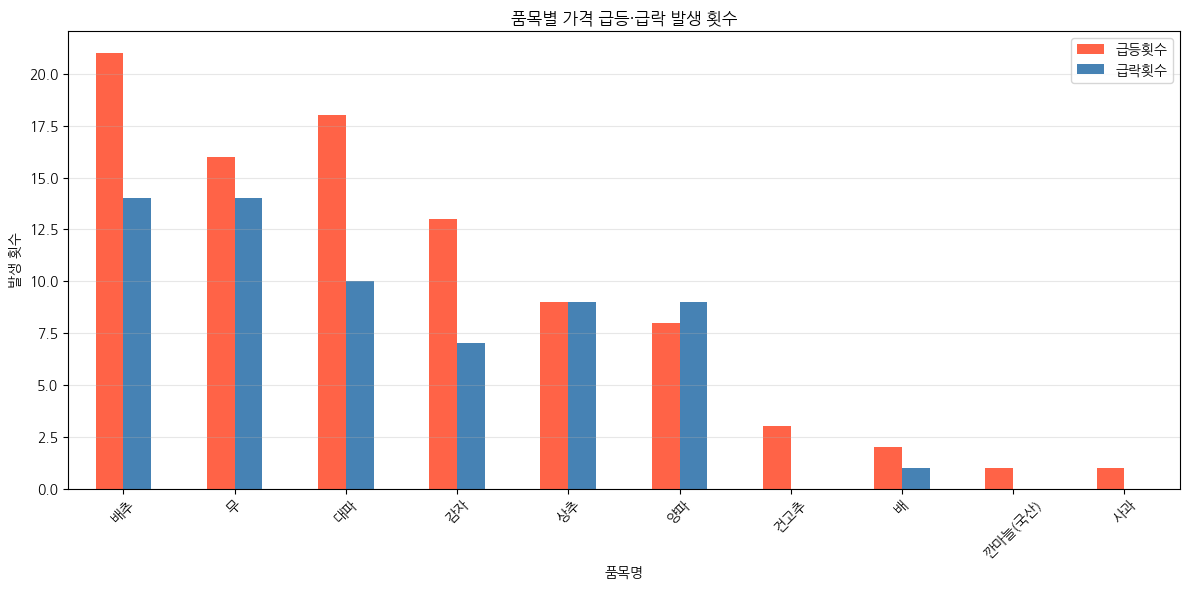

In [19]:
threshold = 20

change_df["급등"] = (
    change_df["가격변화율(%)"] >= threshold
)

change_df["급락"] = (
    change_df["가격변화율(%)"] <= -threshold
)

event_stats = change_df.groupby("품목명").agg(
    급등횟수=("급등", "sum"),
    급락횟수=("급락", "sum")
)

event_stats["총급변동횟수"] = (
    event_stats["급등횟수"] +
    event_stats["급락횟수"]
)

event_stats = event_stats.sort_values(
    "총급변동횟수", ascending=False
)

display(event_stats)

# 시각화
event_stats[["급등횟수", "급락횟수"]].plot(
    kind="bar",
    figsize=(12, 6),
    color=["tomato", "steelblue"]
)

plt.title("품목별 가격 급등·급락 발생 횟수")
plt.xlabel("품목명")
plt.ylabel("발생 횟수")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


가격 수준의 변동성뿐 아니라 단기간의 가격 변화 양상에서도 품목 간 차이가 큼

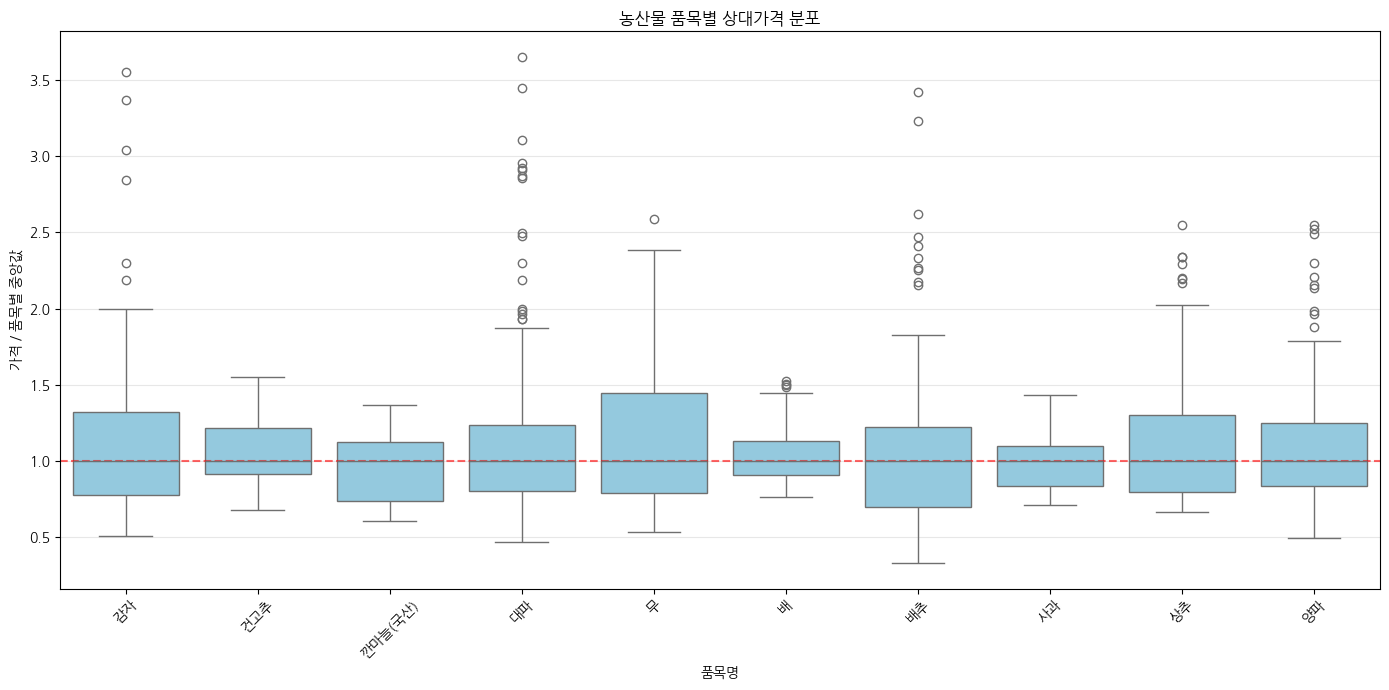

In [20]:
box_df = target_df.copy()

# 품목별 중앙값으로 정규화
box_df["상대가격"] = (
    box_df["평균가격(원)"] /
    box_df.groupby("품목명")["평균가격(원)"]
    .transform("median")
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=box_df,
    x="품목명",
    y="상대가격",
    color="skyblue"
)

plt.axhline(
    1, color="red",
    linestyle="--",
    alpha=0.6
)

plt.title("농산물 품목별 상대가격 분포")
plt.xlabel("품목명")
plt.ylabel("가격 / 품목별 중앙값")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


연도별 가격 변동계수 분석 결과, 동일한 품목에서도 연도에 따라 변동성이 크게 달라지는 것으로 나타났다. 특히 대파는 2021년 61.43%, 배추는 2019년 64.30%의 높은 변동계수를 기록하였다.

직전 순 대비 가격 변화율이 ±20% 이상인 구간을 분석한 결과, 배추(35회), 무(30회), 대파(28회) 순으로 급격한 가격 변동이 빈번하게 나타났다. 반면 사과와 깐마늘은 각각 1회로 상대적으로 안정적인 모습을 보였다.

가격 분포 분석에서는 일부 품목에서 높은 가격의 이상치가 관찰되었다. 이러한 극단값은 실제 시장 상황에 따른 가격 변동을 반영할 가능성이 있으므로, 일괄적으로 제거하기보다 발생 시점과 변동 원인을 추가로 분석할 필요가 있다.

##1.4 월별 가격 계절성 분석

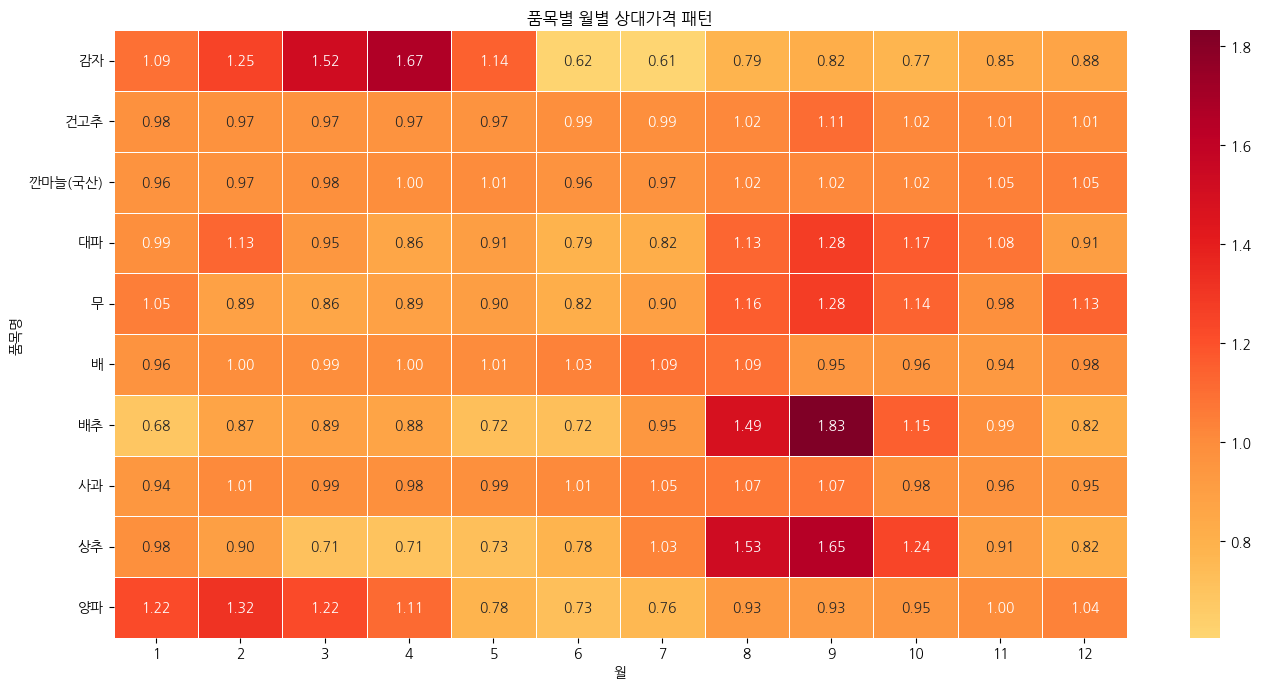

In [21]:
season_df = target_df.copy()

# 품목 및 연도별 평균으로 정규화
season_df["연도별상대가격"] = (
    season_df["평균가격(원)"] /
    season_df.groupby(["품목명", "year"])["평균가격(원)"]
    .transform("mean")
)

# 월별 상대가격 평균
monthly_pattern = season_df.groupby(
    ["품목명", "month"]
)["연도별상대가격"].mean().unstack()

plt.figure(figsize=(14, 7))

sns.heatmap(
    monthly_pattern,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    center=1,
    linewidths=0.5
)

plt.title("품목별 월별 상대가격 패턴")
plt.xlabel("월")
plt.ylabel("품목명")
plt.tight_layout()
plt.show()


배추: 8-9월 가격이 상대적으로 높고, 1월과 5-6월은 낮은 편


상추: 8-9월 가격이 높고, 3-5월은 낮은 편



감자: 3-4월 가격이 높고, 6-7월은 낮은 편



양파: 1-4월 가격이 높고, 5-7월은 낮은 편



건고추·깐마늘: 월별 상대가격 차이가 비교적 작음

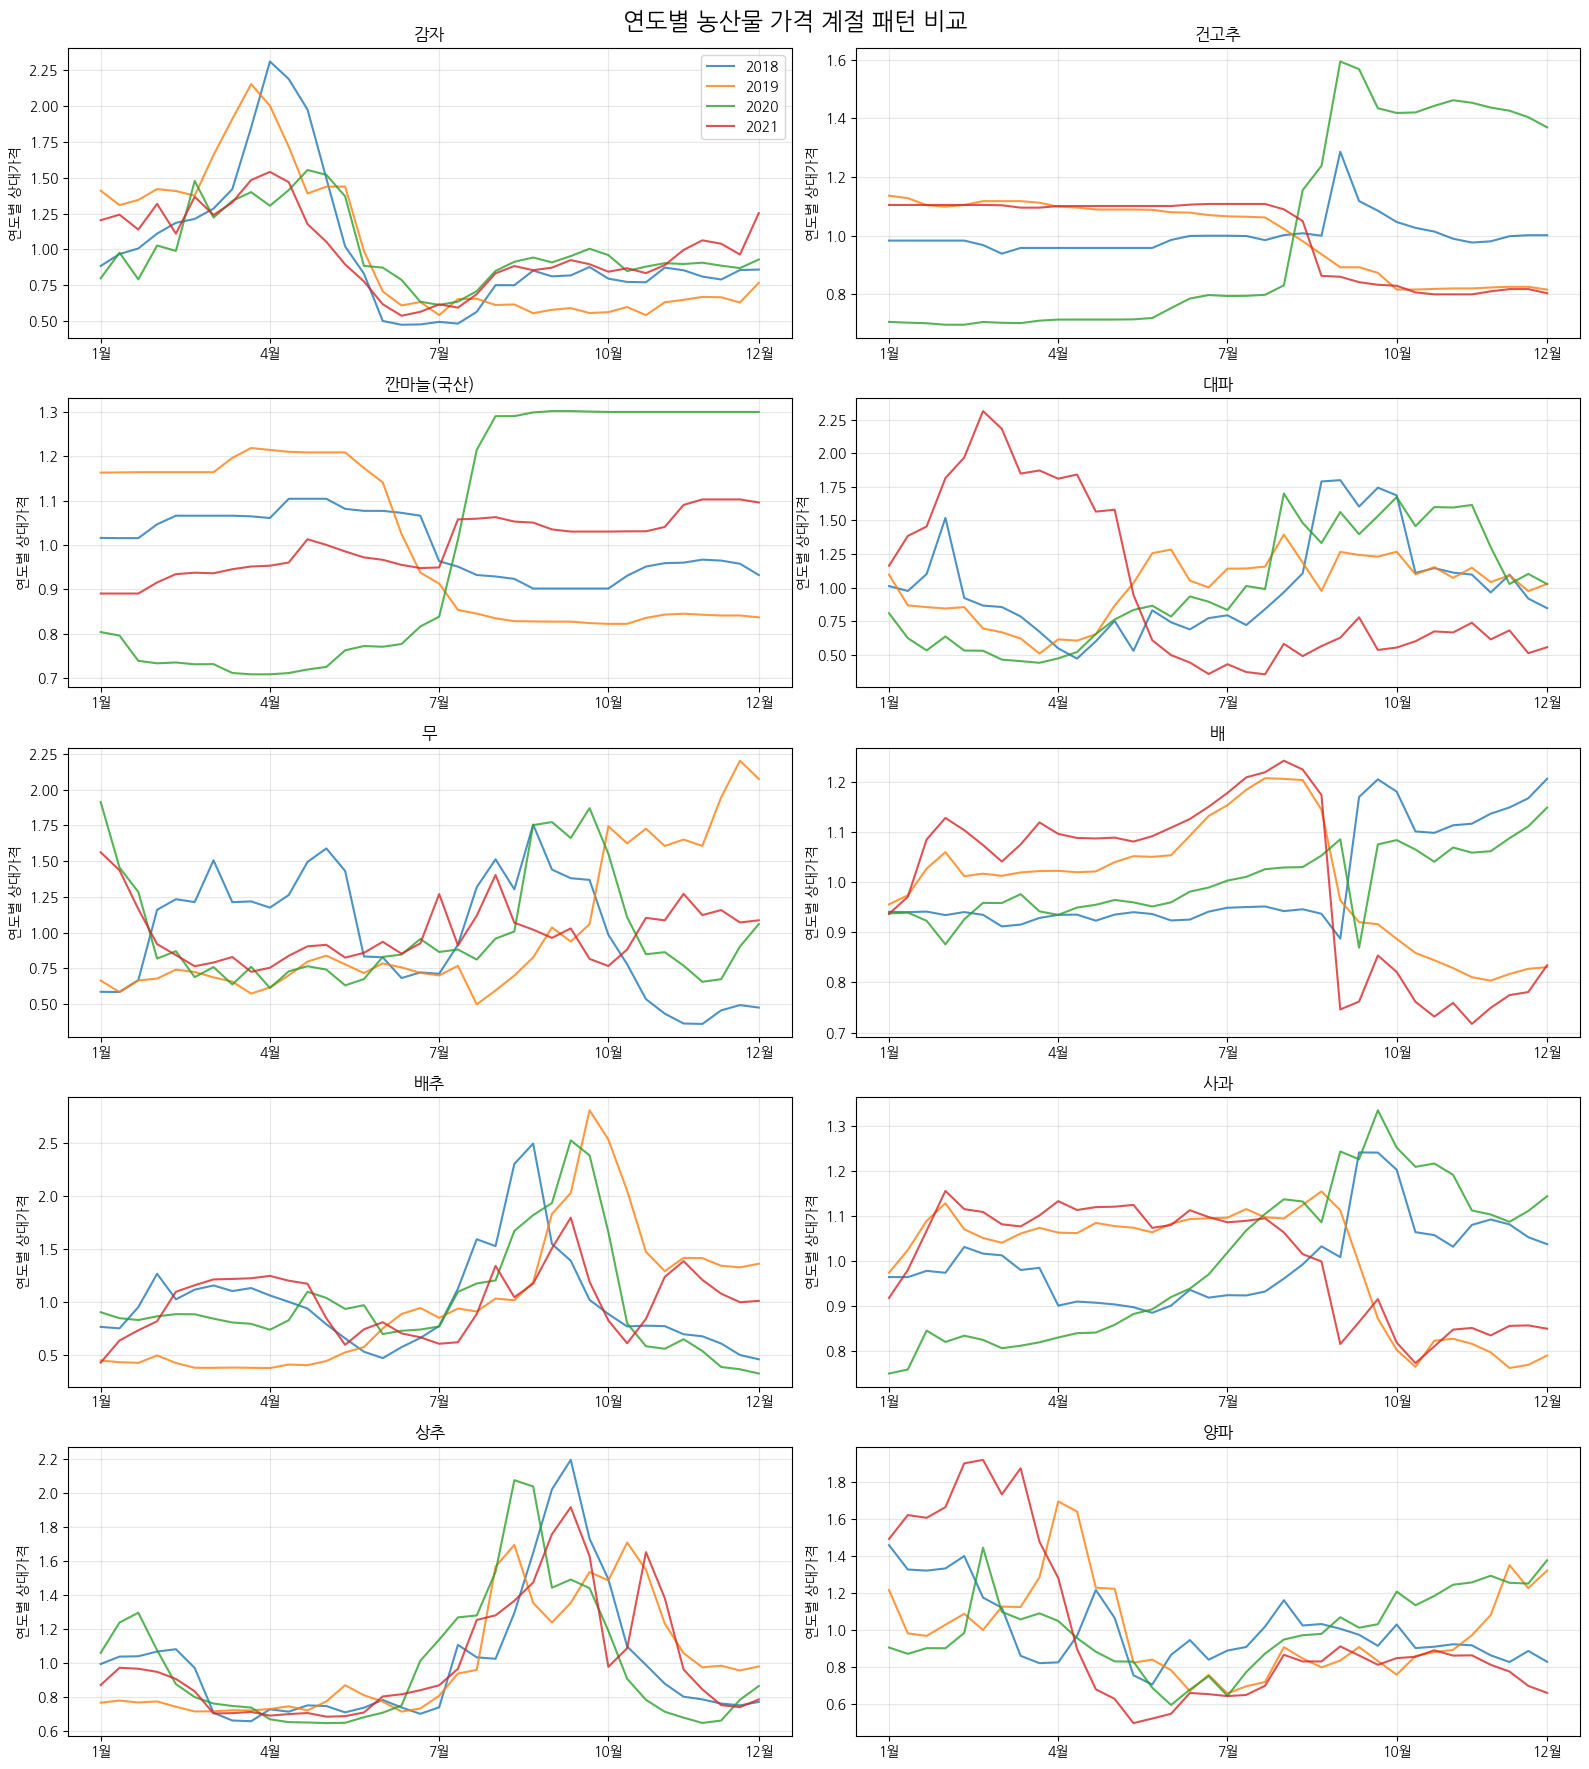

In [22]:
season_df["year_index"] = (
    (season_df["month"] - 1) * 3 +
    season_df["soon"]
)

fig, axes = plt.subplots(5, 2, figsize=(16, 18))
axes = axes.flatten()

for ax, (item, group) in zip(
    axes, season_df.groupby("품목명")
):
    for year, year_data in group.groupby("year"):
        year_data = year_data.sort_values("year_index")

        ax.plot(
            year_data["year_index"],
            year_data["연도별상대가격"],
            label=str(year),
            alpha=0.8
        )

    ax.set_title(item)
    ax.set_xticks([1, 10, 19, 28, 36])
    ax.set_xticklabels(["1월", "4월", "7월", "10월", "12월"])
    ax.set_ylabel("연도별 상대가격")
    ax.grid(alpha=0.3)

axes[0].legend()

plt.suptitle("연도별 농산물 가격 계절 패턴 비교", fontsize=17)
plt.tight_layout()
plt.show()


,상순,중순,하순
품목명,,,
감자,1.006,0.995,0.999
건고추,1.003,1.003,0.994
깐마늘(국산),0.996,1.001,1.003
대파,1.050,0.972,0.977
무,1.025,0.982,0.994
배,0.994,0.996,1.010
배추,0.982,0.999,1.019
사과,0.996,0.998,1.006
상추,0.983,1.010,1.007


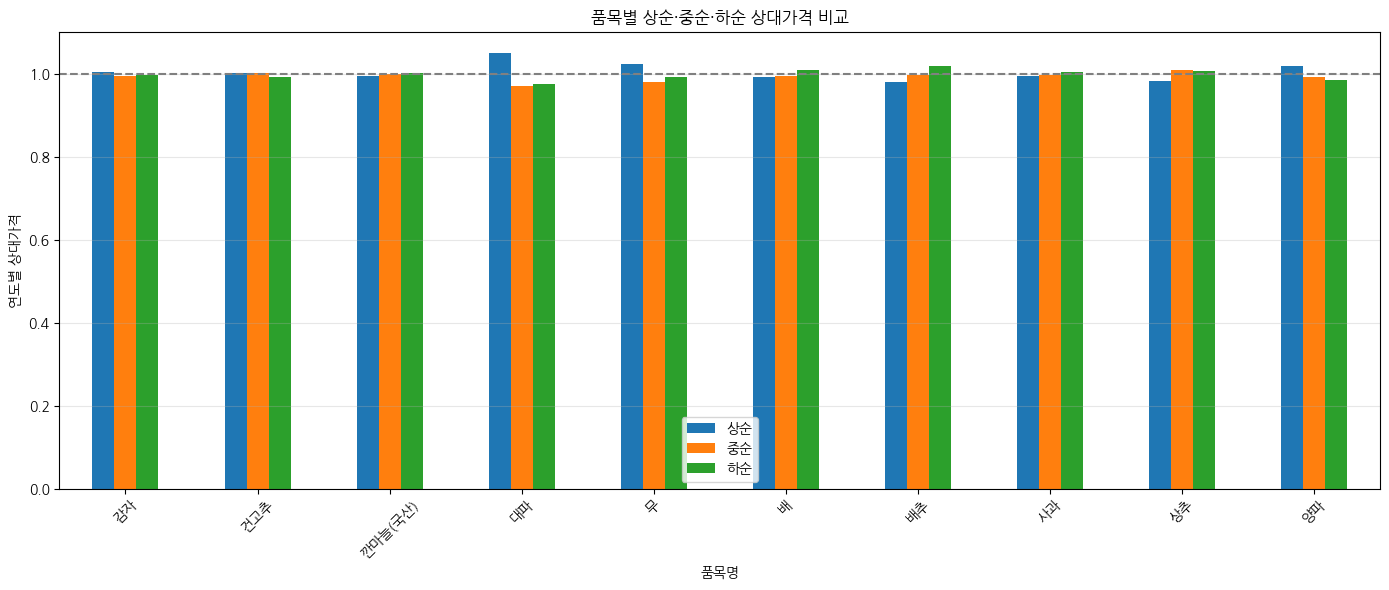

In [23]:
soon_pattern = season_df.groupby(
    ["품목명", "soon"]
)["연도별상대가격"].mean().unstack()

soon_pattern.columns = ["상순", "중순", "하순"]

display(soon_pattern.round(3))

soon_pattern.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("품목별 상순·중순·하순 상대가격 비교")
plt.xlabel("품목명")
plt.ylabel("연도별 상대가격")
plt.xticks(rotation=45)
plt.axhline(1, color="gray", linestyle="--")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


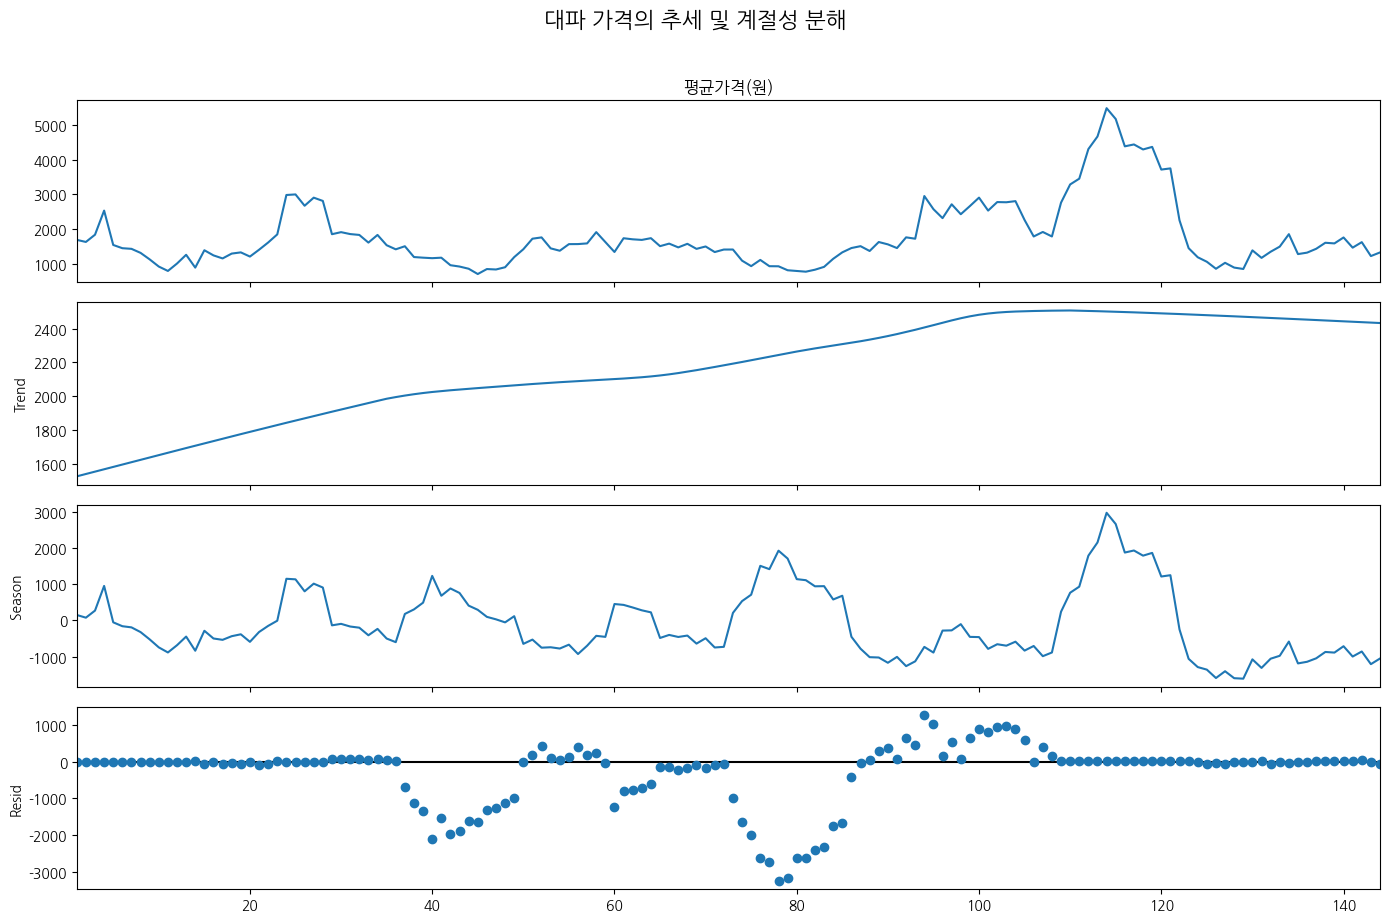

In [24]:
from statsmodels.tsa.seasonal import STL

# 우선 가격 변동성이 큰 대파 분석
item = "대파"

data = target_df[
    target_df["품목명"] == item
].sort_values("time_index")

series = data.set_index(
    "time_index"
)["평균가격(원)"]

# 1년 = 36순
stl = STL(
    series,
    period=36,
    robust=True
)

result = stl.fit()

fig = result.plot()
fig.set_size_inches(14, 9)

plt.suptitle(
    f"{item} 가격의 추세 및 계절성 분해",
    fontsize=16,
    y=1.02
)
plt.tight_layout()
plt.show()


월별 상대가격 분석 결과, 품목에 따라 계절적 가격 패턴의 차이가 관찰되었다. 배추와 상추는 8-9월에 상대적으로 높은 가격을 보였으며, 감자는 3-4월, 양파는 1-4월에 높은 가격 수준을 나타냈다.

연도별 계절 패턴 비교에서도 배추와 상추는 여러 연도에 걸쳐 유사한 시기에 가격이 상승하는 경향을 보였다. 반면 대파는 연도별 변동 양상의 차이가 커 계절성 외의 요인도 고려할 필요가 있었다.

상순·중순·하순의 평균 상대가격 차이는 대부분 크지 않았으며, 월별 계절성이 보다 뚜렷하게 나타났다.

이러한 결과를 바탕으로 향후 가격 예측 모델에서는 최근 가격 변화율 및 이동 변동성과 함께 월별 계절성 정보를 예측 변수로 활용하는 방안을 검토할 수 있다.

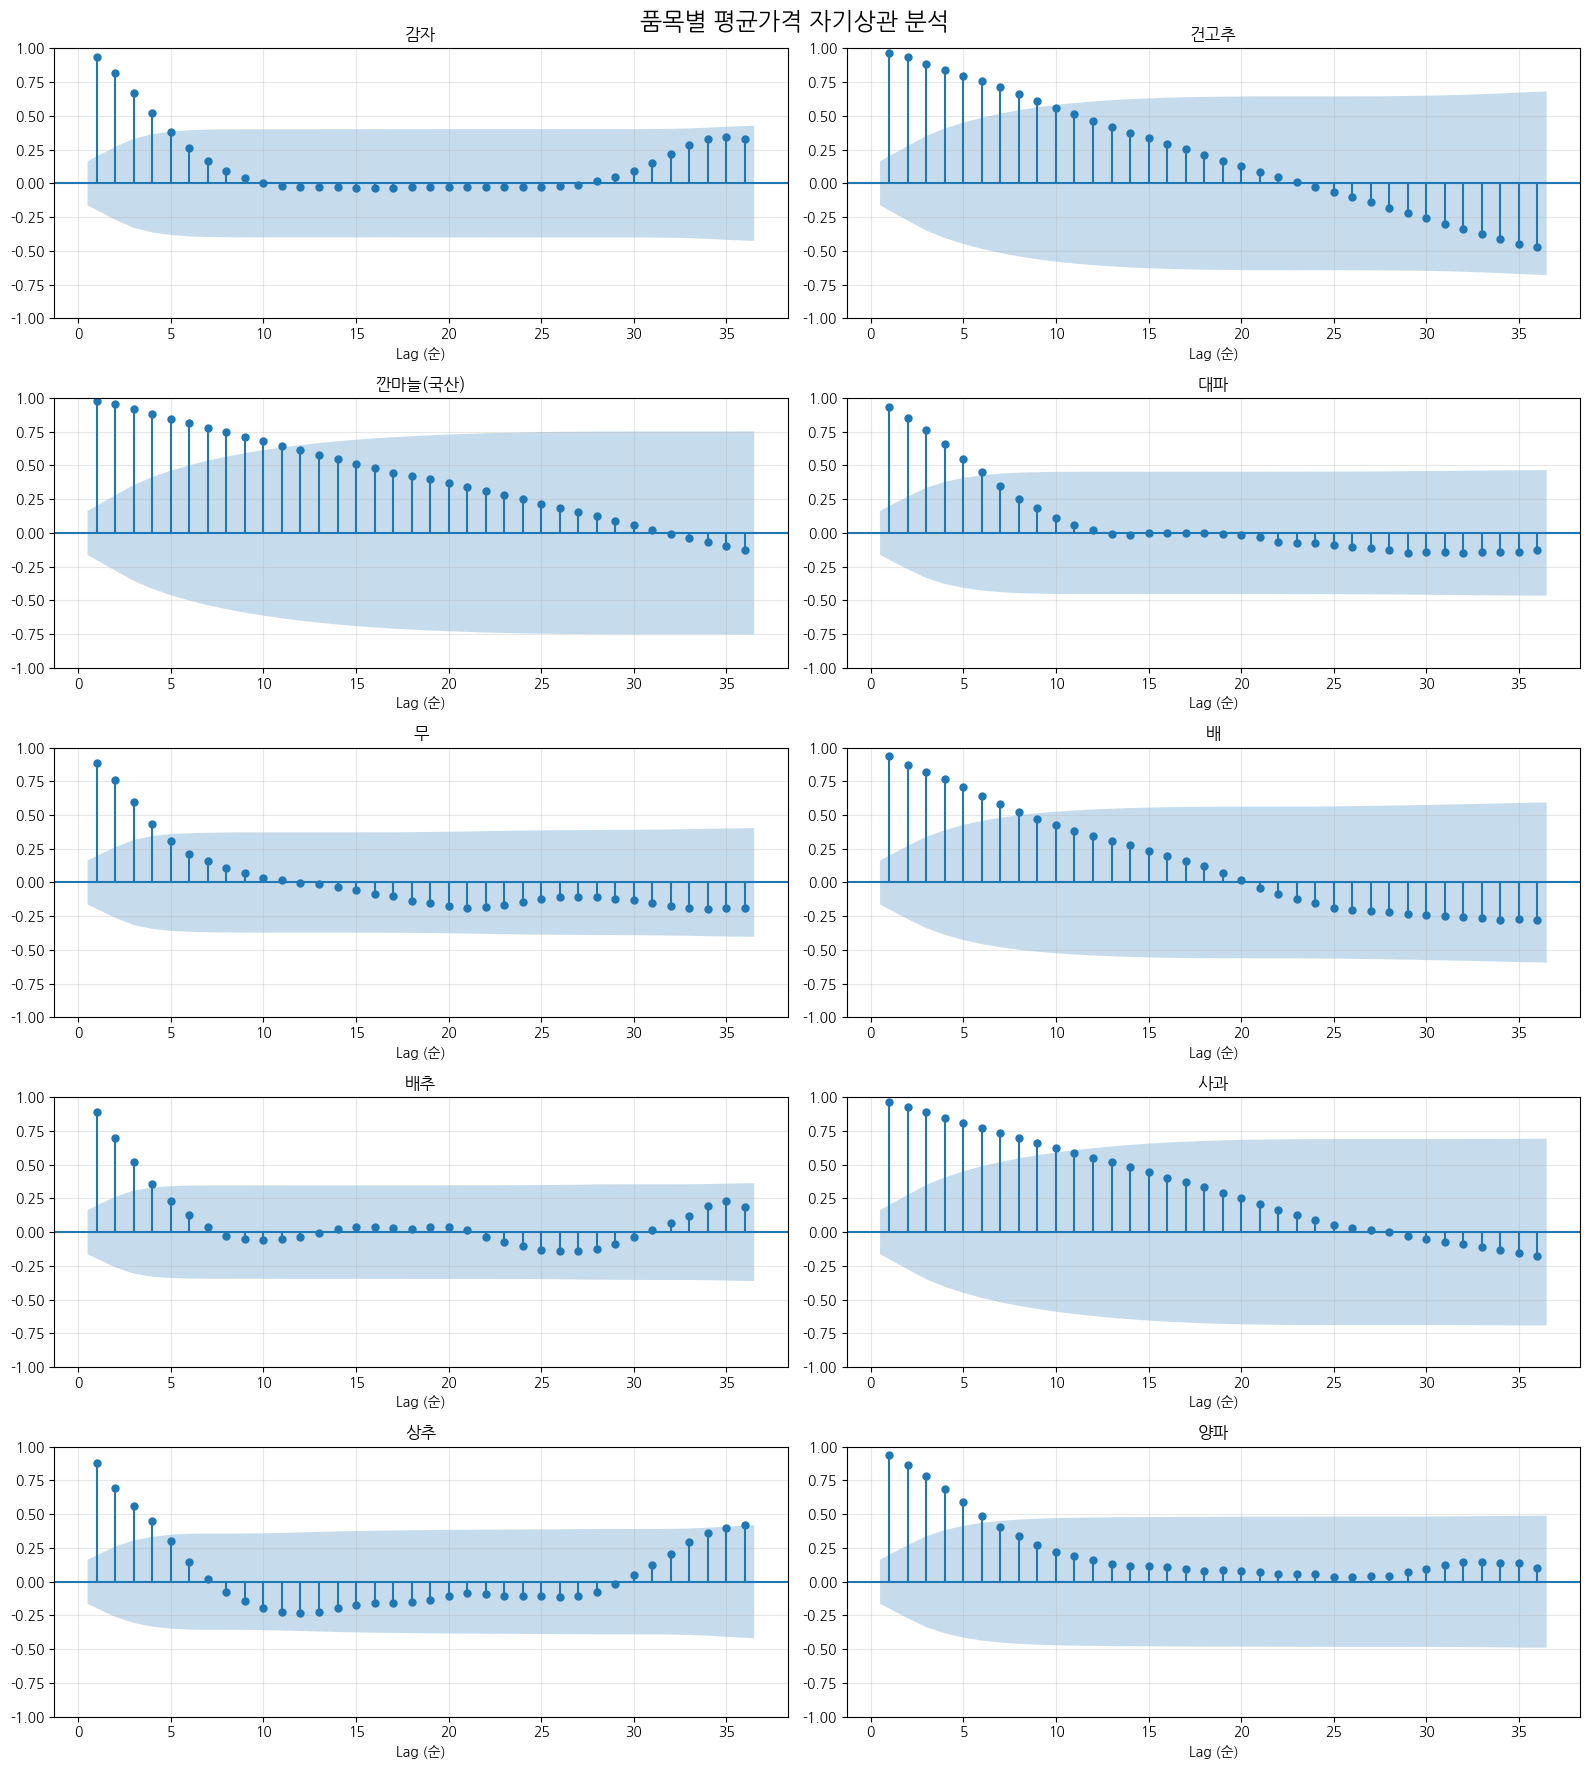

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf

items = sorted(target_df["품목명"].unique())

fig, axes = plt.subplots(5, 2, figsize=(16, 18))

for ax, item in zip(axes.flatten(), items):

    data = target_df[
        target_df["품목명"] == item
    ].sort_values("time_index")

    price = data["평균가격(원)"].reset_index(drop=True)

    plot_acf(
        price,
        lags=36,
        alpha=0.05,
        zero=False,
        ax=ax
    )

    ax.set_title(item)
    ax.set_xlabel("Lag (순)")
    ax.grid(alpha=0.3)

plt.suptitle(
    "품목별 평균가격 자기상관 분석",
    fontsize=17
)

plt.tight_layout()
plt.show()


,Lag_1,Lag_2,Lag_3,Lag_9,Lag_36
품목명,,,,,
감자,0.935,0.820,0.672,0.046,0.617
건고추,0.969,0.933,0.885,0.615,-0.577
깐마늘(국산),0.991,0.973,0.950,0.779,-0.214
대파,0.931,0.856,0.768,0.184,-0.237
무,0.889,0.761,0.600,0.075,-0.236
배,0.944,0.883,0.834,0.500,-0.407
배추,0.889,0.701,0.518,-0.055,0.212
사과,0.970,0.934,0.895,0.675,-0.189
상추,0.882,0.693,0.562,-0.150,0.624


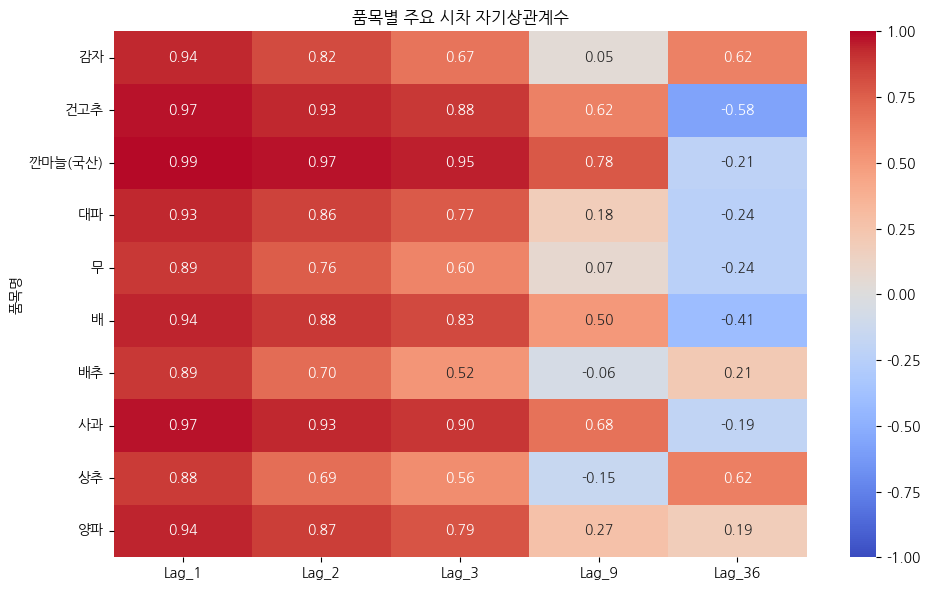

In [26]:
lag_list = [1, 2, 3, 9, 36]

acf_result = []

for item, group in target_df.groupby("품목명"):

    price = group.sort_values(
        "time_index"
    )["평균가격(원)"]

    result = {"품목명": item}

    for lag in lag_list:
        result[f"Lag_{lag}"] = price.autocorr(lag=lag)

    acf_result.append(result)

acf_table = pd.DataFrame(acf_result).set_index("품목명")

display(acf_table.round(3))

plt.figure(figsize=(10, 6))

sns.heatmap(
    acf_table,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("품목별 주요 시차 자기상관계수")
plt.tight_layout()
plt.show()


10개 농산물의 가격 자기상관계수를 분석한 결과, 모든 품목에서 Lag 1 자기상관계수가 0.88 이상으로 나타나 직전 순 가격과 현재 가격 사이에 강한 양의 상관관계가 존재함을 확인하였다.

특히 깐마늘(0.991), 사과(0.970), 건고추(0.969)는 높은 단기 자기상관을 보였으며, 시차가 증가한 이후에도 상대적으로 높은 상관관계를 유지하였다.

반면 배추와 상추는 시차가 증가함에 따라 자기상관계수가 빠르게 감소하는 특징을 보였다.

이러한 결과는 농산물 가격의 시간적 지속성이 품목별로 다름을 보여준다. 따라서 향후 예측 모델에서는 과거 가격을 활용한 Lag 변수와 최근 가격 변화 정보를 함께 고려할 필요가 있다.

##1.5 산지공판장 및 전국도매 데이터 분석

In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

folder = "/content/drive/MyDrive/[ESAA] OB 1조/프로젝트3"

# 폴더의 실제 파일명 확인
print(os.listdir(folder))

# TRAIN 산지공판장 데이터
origin = pd.read_csv(
    f"{folder}/TRAIN_산지공판장_2018-2021.csv"
)

# TRAIN 전국도매 데이터
wholesale = pd.read_csv(
    f"{folder}/TRAIN_전국도매_2018-2021.csv"
)

print("산지공판장:", origin.shape)
print("전국도매:", wholesale.shape)


print("\n산지공판장 컬럼:")
print(origin.columns.tolist())

print("\n전국도매 컬럼:")
print(wholesale.columns.tolist())

print("\n산지공판장 품목:")
print(origin["품목명"].unique())

print("\n전국도매 품목:")
print(wholesale["품목명"].unique())

# 결측치 및 가격 0원 등 확인
for name, data in [
    ("산지공판장", origin),
    ("전국도매", wholesale)
]:
    print(f"\n[{name}]")

    display(data.isnull().sum().to_frame("결측치 수"))

    print(
        "반입량 0 이하:",
        (data["총반입량(kg)"] <= 0).sum()
    )

    print(
        "평균가 0 이하:",
        (data["평균가(원/kg)"] <= 0).sum()
    )


['sample_submission.csv', 'train.csv', 'TRAIN_산지공판장_2018-2021.csv', 'TRAIN_전국도매_2018-2021.csv', 'TEST_20.csv', 'TEST_21.csv', 'TEST_23.csv', 'TEST_22.csv', 'TEST_24.csv', 'TEST_00.csv', 'TEST_02.csv', 'TEST_01.csv', 'TEST_03.csv', 'TEST_04.csv', 'TEST_05.csv', 'TEST_06.csv', 'TEST_07.csv', 'TEST_08.csv', 'TEST_09.csv', 'TEST_10.csv', 'TEST_11.csv', 'TEST_12.csv', 'TEST_13.csv', 'TEST_14.csv', 'TEST_15.csv', 'TEST_16.csv', 'TEST_17.csv', 'TEST_19.csv', 'TEST_18.csv', 'TEST_전국도매_20.csv', 'TEST_전국도매_21.csv', 'TEST_전국도매_22.csv', 'TEST_전국도매_23.csv', 'TEST_전국도매_24.csv', 'TEST_산지공판장_00.csv', 'TEST_산지공판장_01.csv', 'TEST_산지공판장_02.csv', 'TEST_산지공판장_04.csv', 'TEST_산지공판장_03.csv', 'TEST_산지공판장_06.csv', 'TEST_산지공판장_05.csv', 'TEST_산지공판장_07.csv', 'TEST_산지공판장_08.csv', 'TEST_산지공판장_09.csv', 'TEST_산지공판장_10.csv', 'TEST_산지공판장_11.csv', 'TEST_산지공판장_12.

,결측치 수
시점,0
공판장코드,0
공판장명,0
품목코드,0
품목명,0
품종코드,0
품종명,0
등급코드,0
등급명,0
총반입량(kg),0


반입량 0 이하: 10
평균가 0 이하: 10

[전국도매]


,결측치 수
시점,0
시장코드,0
시장명,0
품목코드,0
품목명,0
품종코드,0
품종명,0
총반입량(kg),0
총거래금액(원),0
평균가(원/kg),0


반입량 0 이하: 57
평균가 0 이하: 57


In [28]:
# 목표 품목과 보조 데이터 품목명 매핑
name_map = {
    "깐마늘(국산)": "마늘"
}

def aggregate_market(data, market_col, national_name):

    # 전국 집계 행만 추출
    national = data[
        data[market_col] == national_name
    ].copy()

    # 목표 품목 목록
    target_items = target_df["품목명"].unique()

    national = national[
        national["품목명"].isin(
            ["마늘" if x == "깐마늘(국산)" else x
             for x in target_items]
        )
    ].copy()

    # 같은 시점·품목에 여러 품종이 있으므로 집계
    result = national.groupby(
        ["시점", "품목명"], as_index=False
    ).agg(
        거래량=("총반입량(kg)", "sum"),
        거래금액=("총거래금액(원)", "sum"),
        경매건수=("경매 건수", "sum")
    )

    # kg당 거래금액 기반 가중평균가격
    result["시장평균가격"] = (
        result["거래금액"] /
        result["거래량"].replace(0, np.nan)
    )

    result["품목명"] = result["품목명"].replace({
        "마늘": "깐마늘(국산)"
    })

    return result

origin_agg = aggregate_market(
    origin,
    "공판장명",
    "*전국농협공판장"
)

wholesale_agg = aggregate_market(
    wholesale,
    "시장명",
    "*전국도매시장"
)

print("산지공판장 집계:", origin_agg.shape)
print("전국도매 집계:", wholesale_agg.shape)

display(origin_agg.head())
display(wholesale_agg.head())

# 품목별 관측 시점 확인
print("\n산지공판장 시점 수")
print(origin_agg.groupby("품목명")["시점"].nunique())

print("\n전국도매 시점 수")
print(wholesale_agg.groupby("품목명")["시점"].nunique())


산지공판장 집계: (1296, 6)
전국도매 집계: (1296, 6)


,시점,품목명,거래량,거래금액,경매건수,시장평균가격
0,201801상순,감자,103550.0,183644544,68,1773.486663
1,201801상순,대파,125116.0,177541590,45,1419.015873
2,201801상순,깐마늘(국산),30927.0,114608331,86,3705.769425
3,201801상순,무,327050.0,97869639,57,299.249775
4,201801상순,배,279010.0,438404030,63,1571.284291


,시점,품목명,거래량,거래금액,경매건수,시장평균가격
0,201801상순,감자,5232853.8,9105401015,2782,1740.044986
1,201801상순,대파,6133887.0,8666598958,2708,1412.904893
2,201801상순,깐마늘(국산),723823.2,3497678271,2251,4832.227360
3,201801상순,무,12716845.1,4932025670,1767,387.834060
4,201801상순,배,2687121.6,4093204000,2047,1523.267127



산지공판장 시점 수
품목명
감자         144
깐마늘(국산)    144
대파         144
무          144
배          144
배추         144
사과         144
상추         144
양파         144
Name: 시점, dtype: int64

전국도매 시점 수
품목명
감자         144
깐마늘(국산)    144
대파         144
무          144
배          144
배추         144
사과         144
상추         144
양파         144
Name: 시점, dtype: int64


/tmp/ipykernel_966/2189665727.py:55: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


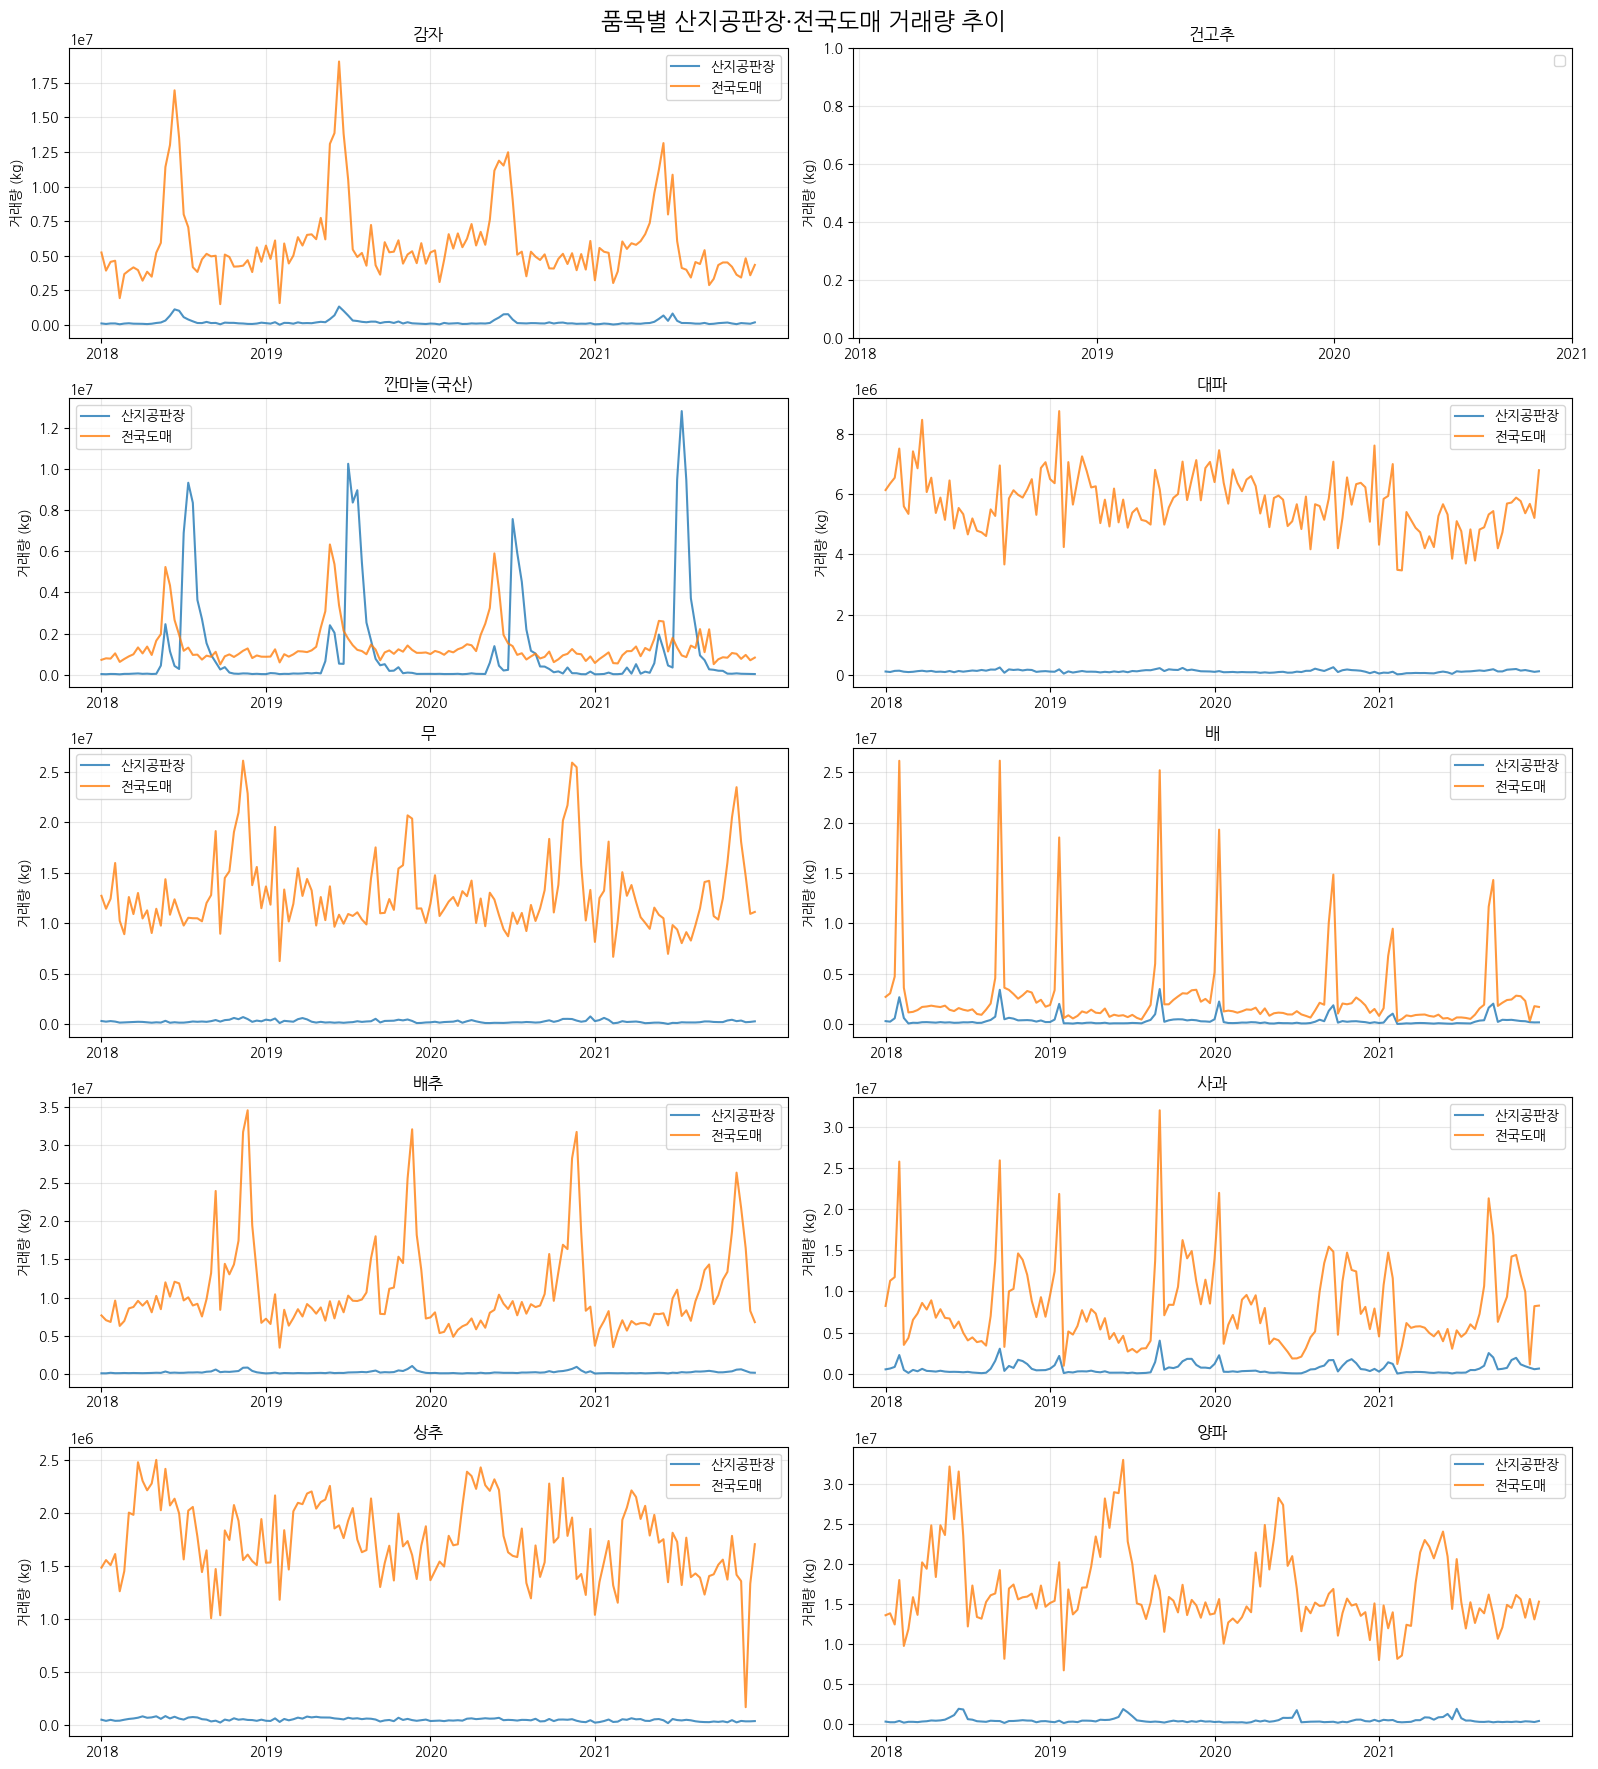

In [29]:
fig, axes = plt.subplots(5, 2, figsize=(16, 18))
axes = axes.flatten()

items = sorted(target_df["품목명"].unique())

for ax, item in zip(axes, items):

    o = origin_agg[
        origin_agg["품목명"] == item
    ].copy()

    w = wholesale_agg[
        wholesale_agg["품목명"] == item
    ].copy()

    # time_index 생성
    def make_index(data):
        data = data.copy()
        data["year"] = data["시점"].str[:4].astype(int)
        data["month"] = data["시점"].str[4:6].astype(int)
        data["soon"] = data["시점"].str[-2:].map({
            "상순": 1, "중순": 2, "하순": 3
        })
        data["time_index"] = (
            (data["year"] - 2018) * 36 +
            (data["month"] - 1) * 3 +
            data["soon"]
        )
        return data

    o = make_index(o)
    w = make_index(w)

    if len(o) > 0:
        ax.plot(
            o["time_index"],
            o["거래량"],
            label="산지공판장",
            alpha=0.8
        )

    if len(w) > 0:
        ax.plot(
            w["time_index"],
            w["거래량"],
            label="전국도매",
            alpha=0.8
        )

    ax.set_title(item)
    ax.set_xticks([1, 37, 73, 109])
    ax.set_xticklabels(["2018", "2019", "2020", "2021"])
    ax.set_ylabel("거래량 (kg)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "품목별 산지공판장·전국도매 거래량 추이",
    fontsize=17
)
plt.tight_layout()
plt.show()


In [30]:
origin_sub = origin_agg.rename(columns={
    "거래량": "산지거래량",
    "시장평균가격": "산지가격",
    "경매건수": "산지경매건수"
})

wholesale_sub = wholesale_agg.rename(columns={
    "거래량": "도매거래량",
    "시장평균가격": "도매가격",
    "경매건수": "도매경매건수"
})

eda_merged = target_df.merge(
    origin_sub[
        ["시점", "품목명", "산지거래량",
         "산지가격", "산지경매건수"]
    ],
    on=["시점", "품목명"],
    how="left",
    validate="one_to_one"
)

eda_merged = eda_merged.merge(
    wholesale_sub[
        ["시점", "품목명", "도매거래량",
         "도매가격", "도매경매건수"]
    ],
    on=["시점", "품목명"],
    how="left",
    validate="one_to_one"
)

eda_merged = eda_merged.sort_values(
    ["품목명", "time_index"]
).reset_index(drop=True)

print("병합 후 데이터:", eda_merged.shape)

print("\n보조 데이터 결측치:")
display(
    eda_merged[
        ["산지거래량", "산지가격",
         "도매거래량", "도매가격"]
    ].isnull().sum()
)

print("\n품목별 보조 데이터 관측 개수:")
display(
    eda_merged.groupby("품목명")[
        ["산지가격", "도매가격"]
    ].count()
)


병합 후 데이터: (1440, 17)

보조 데이터 결측치:


,0
산지거래량,144
산지가격,144
도매거래량,144
도매가격,144



품목별 보조 데이터 관측 개수:


,산지가격,도매가격
품목명,,
감자,144,144
건고추,0,0
깐마늘(국산),144,144
대파,144,144
무,144,144
배,144,144
배추,144,144
사과,144,144
상추,144,144


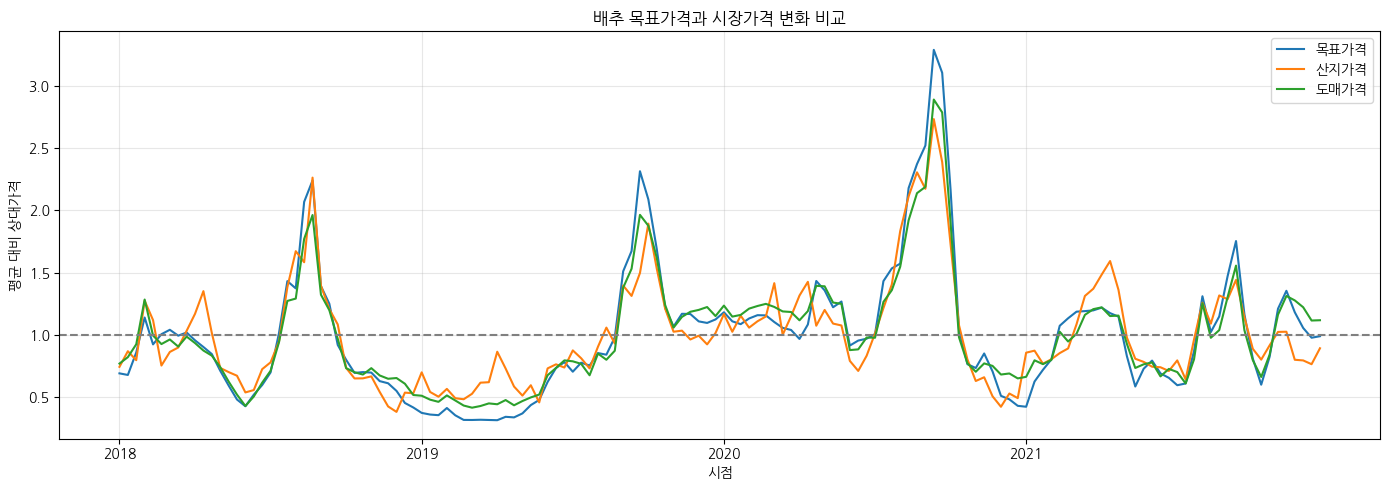

In [31]:
item = "배추"

data = eda_merged[
    eda_merged["품목명"] == item
].sort_values("time_index").copy()

cols = {
    "평균가격(원)": "목표가격",
    "산지가격": "산지가격",
    "도매가격": "도매가격"
}

plt.figure(figsize=(14, 5))

for col, label in cols.items():

    series = data[col]

    # 평균 대비 상대가격으로 정규화
    if series.notna().sum() == 0:
        continue

    normalized = series / series.mean()

    plt.plot(
        data["time_index"],
        normalized,
        label=label
    )

plt.title(f"{item} 목표가격과 시장가격 변화 비교")
plt.xlabel("시점")
plt.ylabel("평균 대비 상대가격")
plt.xticks(
    [1, 37, 73, 109],
    ["2018", "2019", "2020", "2021"]
)
plt.axhline(1, color="gray", linestyle="--")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,산지거래량_상관,도매거래량_상관,산지가격_상관,도매가격_상관
품목명,,,,
감자,-0.358,-0.298,0.919,0.951
건고추,NaN,NaN,NaN,NaN
깐마늘(국산),-0.016,-0.153,0.510,0.787
대파,-0.141,-0.293,0.955,0.991
무,-0.110,-0.087,0.961,0.979
배,-0.129,-0.141,0.841,0.845
배추,0.103,0.023,0.918,0.986
사과,-0.053,-0.124,0.626,0.542
상추,-0.452,-0.483,0.895,0.849


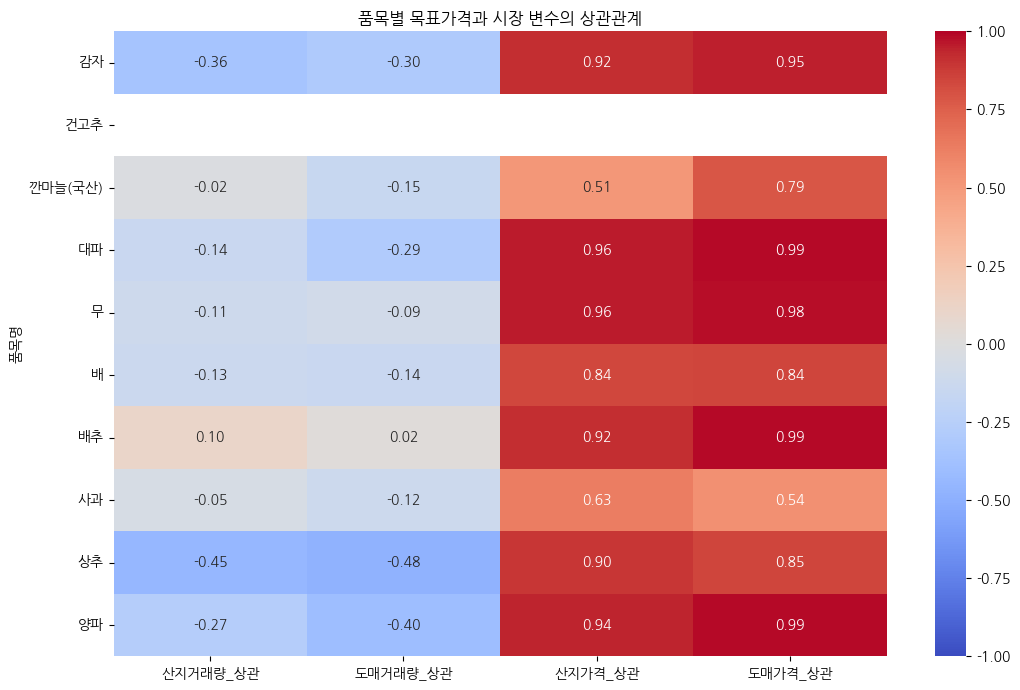

In [32]:
corr_results = []

for item, group in eda_merged.groupby("품목명"):

    result = {
        "품목명": item,
        "산지거래량_상관": group["평균가격(원)"].corr(
            group["산지거래량"]
        ),
        "도매거래량_상관": group["평균가격(원)"].corr(
            group["도매거래량"]
        ),
        "산지가격_상관": group["평균가격(원)"].corr(
            group["산지가격"]
        ),
        "도매가격_상관": group["평균가격(원)"].corr(
            group["도매가격"]
        )
    }

    corr_results.append(result)

corr_df = pd.DataFrame(corr_results).set_index("품목명")

display(corr_df.round(3))

plt.figure(figsize=(11, 7))

sns.heatmap(
    corr_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("품목별 목표가격과 시장 변수의 상관관계")
plt.tight_layout()
plt.show()


산지공판장 및 전국도매 데이터의 거래량과 시장가격이 목표 평균가격과 어떤 관계를 갖는지 분석하였다.

시장가격의 경우 대부분의 품목에서 목표가격과 높은 양의 상관관계가 나타났다. 특히 대파(0.991), 배추(0.986), 양파(0.985), 무(0.979)는 전국도매 가격과 매우 높은 상관계수를 보였다.

반면 거래량과 가격의 관계는 품목별로 차이가 있었다. 상추와 양파는 전국도매 거래량과 목표가격 사이에 각각 -0.483, -0.401의 음의 상관관계가 관찰되었지만, 배추는 0.023으로 선형 상관관계가 거의 나타나지 않았다.

이러한 결과는 시장가격과 거래량이 가격 예측에 활용할 수 있는 후보 변수임을 보여준다. 다만 같은 시점의 상관관계만으로 예측력을 판단할 수 없으므로 미래 가격과의 시차 관계를 추가로 분석할 필요가 있다.

,품목명,예측시점,변수,상관계수,표본수
0,감자,T+1,산지거래량,-0.386,143
1,감자,T+1,도매거래량,-0.359,143
2,감자,T+1,산지가격,0.835,143
3,감자,T+1,도매가격,0.865,143
4,감자,T+2,산지거래량,-0.387,142
...,...,...,...,...,...
115,양파,T+2,도매가격,0.875,142
116,양파,T+3,산지거래량,-0.211,141
117,양파,T+3,도매거래량,-0.489,141
118,양파,T+3,산지가격,0.726,141


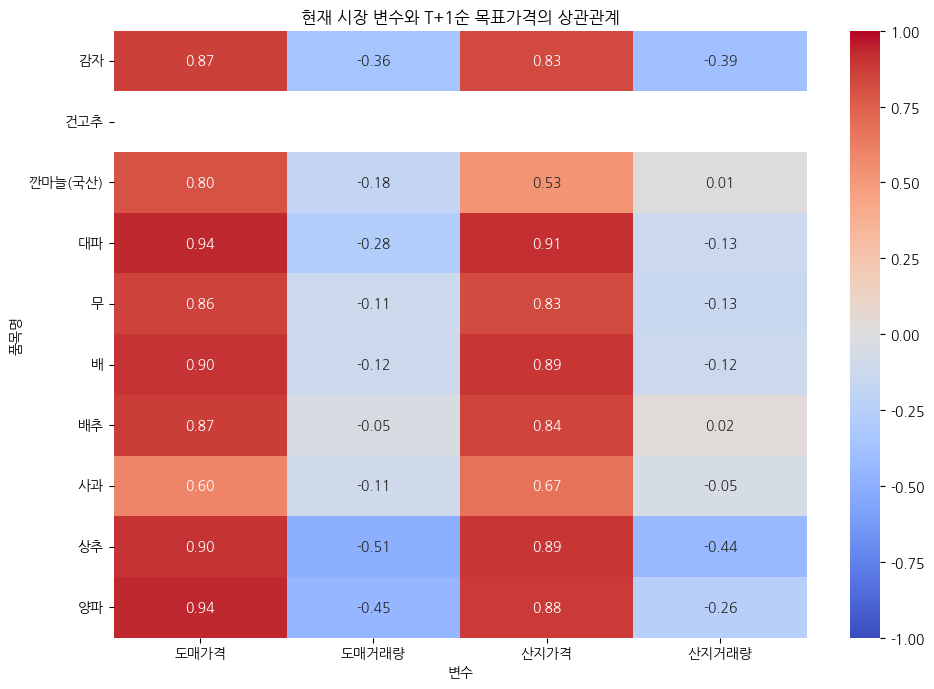

In [33]:
lag_corr_results = []

features = [
    "산지거래량",
    "도매거래량",
    "산지가격",
    "도매가격"
]

for item, group in eda_merged.groupby("품목명"):

    group = group.sort_values("time_index").copy()

    for horizon in [1, 2, 3]:

        # 현재 시점 T에서 미래 가격 생성
        future_price = group["평균가격(원)"].shift(
            -horizon
        )

        for feature in features:

            pair = pd.DataFrame({
                "x": group[feature],
                "y": future_price
            }).dropna()

            corr = (
                pair["x"].corr(pair["y"])
                if len(pair) >= 3 else np.nan
            )

            lag_corr_results.append({
                "품목명": item,
                "예측시점": f"T+{horizon}",
                "변수": feature,
                "상관계수": corr,
                "표본수": len(pair)
            })

lag_corr_df = pd.DataFrame(lag_corr_results)

display(lag_corr_df.round(3))

# 미래 1순 가격과의 관계 시각화
lag1_corr = lag_corr_df[
    lag_corr_df["예측시점"] == "T+1"
].pivot(
    index="품목명",
    columns="변수",
    values="상관계수"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    lag1_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("현재 시장 변수와 T+1순 목표가격의 상관관계")
plt.tight_layout()
plt.show()


현재 시점의 산지공판장·전국도매 가격 및 거래량과 미래 1순 목표가격 사이의 상관관계를 분석하였다.

분석 결과, 현재 도매가격과 미래 1순 목표가격 사이에서는 대파(0.94), 양파(0.94), 배(0.90) 등 여러 품목에서 높은 양의 상관관계가 나타났다.

거래량의 경우 상추에서 현재 도매거래량과 미래 1순 가격의 상관계수가 -0.51로 나타나 상대적으로 뚜렷한 음의 관계가 관찰되었다.

이는 시장가격과 거래량이 미래 가격과 관련된 정보를 포함할 가능성을 보여준다. 다만 가격의 자기상관 및 계절성으로 인한 영향이 존재할 수 있으므로, 실제 모델링에서는 보조 변수를 추가했을 때 예측 성능이 개선되는지 검증할 필요가 있다.

##1.6 예측 모델을 위한 변수 탐색

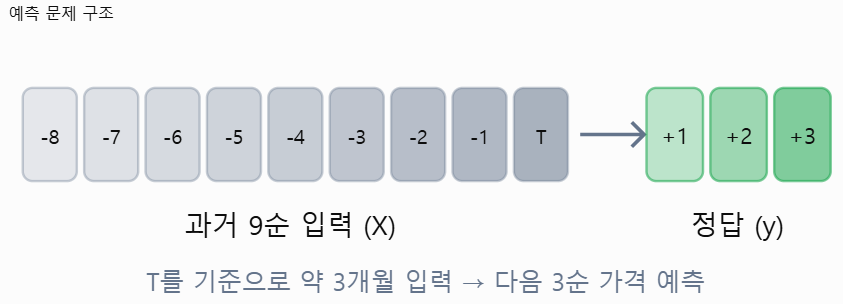

과거 가격(Lag) 변수 생성

In [34]:

import pandas as pd
import numpy as np

# 기존 전처리 완료 데이터 사용
feature_df = target_df.sort_values(
    ["품목명", "time_index"]
).copy()

# 현재 가격 T
feature_df["price_lag_0"] = feature_df["평균가격(원)"]

# 과거 1~8순 가격
for lag in range(1, 9):

    feature_df[f"price_lag_{lag}"] = (
        feature_df.groupby("품목명")["평균가격(원)"]
        .shift(lag)
    )

lag_cols = [
    f"price_lag_{i}" for i in range(9)
]

print("생성된 Lag 변수:")
print(lag_cols)

display(
    feature_df[
        ["품목명", "시점"] + lag_cols
    ].tail(10)
)


생성된 Lag 변수:
['price_lag_0', 'price_lag_1', 'price_lag_2', 'price_lag_3', 'price_lag_4', 'price_lag_5', 'price_lag_6', 'price_lag_7', 'price_lag_8']


,품목명,시점,price_lag_0,price_lag_1,price_lag_2,price_lag_3,price_lag_4,price_lag_5,price_lag_6,price_lag_7,price_lag_8
1430,양파,202109하순,854.833333,907.857143,959.666667,874.000000,873.888889,911.857143,735.500000,683.375000,676.666667
1431,양파,202110상순,892.875000,854.833333,907.857143,959.666667,874.000000,873.888889,911.857143,735.500000,683.375000
1432,양파,202110중순,900.333333,892.875000,854.833333,907.857143,959.666667,874.000000,873.888889,911.857143,735.500000
1433,양파,202110하순,937.333333,900.333333,892.875000,854.833333,907.857143,959.666667,874.000000,873.888889,911.857143
1434,양파,202111상순,907.333333,937.333333,900.333333,892.875000,854.833333,907.857143,959.666667,874.000000,873.888889
1435,양파,202111중순,908.666667,907.333333,937.333333,900.333333,892.875000,854.833333,907.857143,959.666667,874.000000
1436,양파,202111하순,855.000000,908.666667,907.333333,937.333333,900.333333,892.875000,854.833333,907.857143,959.666667
1437,양파,202112상순,816.333333,855.000000,908.666667,907.333333,937.333333,900.333333,892.875000,854.833333,907.857143
1438,양파,202112중순,734.875000,816.333333,855.000000,908.666667,907.333333,937.333333,900.333333,892.875000,854.833333
1439,양파,202112하순,695.100000,734.875000,816.333333,855.000000,908.666667,907.333333,937.333333,900.333333,892.875000


시계열 자기상관 분석 결과를 바탕으로 현재 시점(T)부터 과거 8순(T-8)까지 총 9개의 가격 변수를 생성하였다.

이를 통해 최근 약 3개월 동안의 가격 흐름을 개별 변수로 표현하였으며, 과거 가격과 현재 가격 사이의 높은 자기상관을 고려할 때 해당 변수들은 미래 가격 예측에 유용한 정보를 제공할 가능성이 있다.

In [35]:
grouped = feature_df.groupby("품목명")["평균가격(원)"]

# 이동평균
for window in [3, 6, 9]:

    feature_df[f"rolling_mean_{window}"] = (
        grouped.transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

# 이동표준편차
for window in [3, 6, 9]:

    feature_df[f"rolling_std_{window}"] = (
        grouped.transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).std()
        )
    )

# 최근 9순 변동계수
feature_df["rolling_cv_9"] = (
    feature_df["rolling_std_9"] /
    feature_df["rolling_mean_9"] * 100
)

display(
    feature_df[
        ["품목명", "시점",
         "rolling_mean_3",
         "rolling_mean_6",
         "rolling_mean_9",
         "rolling_std_9",
         "rolling_cv_9"]
    ].tail(10).round(2)
)


,품목명,시점,rolling_mean_3,rolling_mean_6,rolling_mean_9,rolling_std_9,rolling_cv_9
1430,양파,202109하순,907.45,897.02,830.85,104.87,12.62
1431,양파,202110상순,885.19,893.85,854.87,88.65,10.37
1432,양파,202110중순,882.68,898.26,878.98,61.54,7.00
1433,양파,202110하순,910.18,908.82,901.40,32.76,3.63
1434,양파,202111상순,915.00,900.09,900.90,32.62,3.62
1435,양파,202111중순,917.78,900.23,904.77,31.04,3.43
1436,양파,202111하순,890.33,900.26,902.66,33.91,3.76
1437,양파,202112상순,860.00,887.50,886.73,37.28,4.20
1438,양파,202112중순,802.07,859.92,867.51,61.65,7.11
1439,양파,202112하순,748.77,819.55,849.76,84.51,9.94


최근 가격의 전반적인 수준과 변동성을 파악하기 위해 3순, 6순, 9순 이동평균 및 이동표준편차를 생성하고, 최근 9순의 변동계수를 추가하였다.

예를 들어 2021년 12월 하순 양파의 현재 평균가격은 약 695.10원이었으나, 최근 9순 이동평균은 약 849.76원으로 나타나 최근 가격이 과거 평균 수준보다 낮아진 상태임을 확인하였다.

이러한 변수들은 단순한 가격 수준뿐 아니라 최근 가격의 추세 및 변동성 정보를 함께 제공한다.

In [36]:
# 직전 순 대비 변화율
feature_df["change_1"] = (
    feature_df["price_lag_0"] /
    feature_df["price_lag_1"] - 1
)

# 3순 전 대비 변화율
feature_df["change_3"] = (
    feature_df["price_lag_0"] /
    feature_df["price_lag_3"] - 1
)

# 8순 전 대비 변화율
feature_df["change_8"] = (
    feature_df["price_lag_0"] /
    feature_df["price_lag_8"] - 1
)

display(
    feature_df[
        ["품목명", "시점",
         "change_1", "change_3", "change_8"]
    ].tail(10).round(3)
)


,품목명,시점,change_1,change_3,change_8
1430,양파,202109하순,-0.058,-0.022,0.263
1431,양파,202110상순,0.045,-0.070,0.307
1432,양파,202110중순,0.008,-0.008,0.224
1433,양파,202110하순,0.041,0.097,0.028
1434,양파,202111상순,-0.032,0.016,0.038
1435,양파,202111중순,0.001,0.009,0.040
1436,양파,202111하순,-0.059,-0.088,-0.109
1437,양파,202112상순,-0.045,-0.100,-0.101
1438,양파,202112중순,-0.100,-0.191,-0.140
1439,양파,202112하순,-0.054,-0.187,-0.222


In [37]:
feature_df["normal_price_ratio"] = (
    feature_df["평균가격(원)"] /
    feature_df["평년 평균가격(원)"].replace(0, np.nan)
)

display(
    feature_df[
        ["품목명", "시점",
         "평균가격(원)",
         "평년 평균가격(원)",
         "normal_price_ratio"]
    ].tail(10).round(3)
)


,품목명,시점,평균가격(원),평년 평균가격(원),normal_price_ratio
1430,양파,202109하순,854.833,903.644,0.946
1431,양파,202110상순,892.875,1010.060,0.884
1432,양파,202110중순,900.333,933.449,0.965
1433,양파,202110하순,937.333,933.074,1.005
1434,양파,202111상순,907.333,979.704,0.926
1435,양파,202111중순,908.667,975.958,0.931
1436,양파,202111하순,855.000,952.704,0.897
1437,양파,202112상순,816.333,986.458,0.828
1438,양파,202112중순,734.875,960.250,0.765
1439,양파,202112하순,695.100,978.630,0.710


가격의 단기 및 중기 변화 방향을 파악하기 위해 직전 1순, 3순, 8순 대비 가격 변화율을 생성하였다. 또한 현재 평균가격을 평년 평균가격으로 나눈 평년 대비 가격비율을 산출하였다.

2021년 12월 하순 양파는 직전 순 대비 약 5.4%, 3순 전 대비 약 18.7%, 8순 전 대비 약 22.2% 하락한 것으로 나타났다. 평년 대비 가격비율은 0.710으로, 현재 가격이 평년 평균보다 약 29.0% 낮은 수준임을 확인하였다.

이를 통해 가격 변화율은 최근 가격의 상승·하락 방향을, 평년 대비 가격비율은 일반적인 가격 수준과의 차이를 나타내는 변수로 활용할 수 있음을 확인하였다.

In [38]:

market_cols = [
    "산지거래량",
    "산지가격",
    "도매거래량",
    "도매가격"
]

# 기존 시장 변수 제거 후 다시 병합
feature_df = feature_df.drop(
    columns=market_cols,
    errors="ignore"
)

feature_df = feature_df.merge(
    eda_merged[
        ["시점", "품목명"] + market_cols
    ],
    on=["시점", "품목명"],
    how="left",
    validate="one_to_one"
)

feature_df = feature_df.sort_values(
    ["품목명", "time_index"]
).reset_index(drop=True)

# 품목별 보조 변수 관측률
market_coverage = (
    feature_df.groupby("품목명")[market_cols]
    .apply(lambda x: x.notna().mean() * 100)
)

print("품목별 보조 변수 관측률 (%)")
display(market_coverage.round(1))

print("최종 데이터:", feature_df.shape)


품목별 보조 변수 관측률 (%)


,산지거래량,산지가격,도매거래량,도매가격
품목명,,,,
감자,100.0,100.0,100.0,100.0
건고추,0.0,0.0,0.0,0.0
깐마늘(국산),100.0,100.0,100.0,100.0
대파,100.0,100.0,100.0,100.0
무,100.0,100.0,100.0,100.0
배,100.0,100.0,100.0,100.0
배추,100.0,100.0,100.0,100.0
사과,100.0,100.0,100.0,100.0
상추,100.0,100.0,100.0,100.0


최종 데이터: (1440, 35)


In [39]:
price_features = [
    f"price_lag_{i}" for i in range(9)
]

trend_features = [
    "rolling_mean_3",
    "rolling_mean_6",
    "rolling_mean_9",
    "rolling_std_3",
    "rolling_std_6",
    "rolling_std_9",
    "rolling_cv_9",
    "change_1",
    "change_3",
    "change_8"
]

normal_features = [
    "normal_price_ratio"
]

market_features = [
    "산지가격",
    "도매가격",
    "산지거래량",
    "도매거래량"
]

feature_groups = {
    "과거 가격": price_features,
    "추세 및 변동성": trend_features,
    "평년 대비 가격": normal_features,
    "시장 변수": market_features
}

summary = []

for group_name, cols in feature_groups.items():
    for col in cols:
        summary.append({
            "변수그룹": group_name,
            "변수명": col,
            "생성여부": col in feature_df.columns,
            "결측률(%)": (
                feature_df[col].isna().mean() * 100
                if col in feature_df.columns else np.nan
            )
        })

feature_summary = pd.DataFrame(summary)

display(feature_summary.round(2))

print("전체 변수 후보 수:", len(feature_summary))
print("정상 생성 변수 수:",
      feature_summary["생성여부"].sum())


,변수그룹,변수명,생성여부,결측률(%)
0,과거 가격,price_lag_0,True,0.00
1,과거 가격,price_lag_1,True,0.69
2,과거 가격,price_lag_2,True,1.39
3,과거 가격,price_lag_3,True,2.08
4,과거 가격,price_lag_4,True,2.78
5,과거 가격,price_lag_5,True,3.47
6,과거 가격,price_lag_6,True,4.17
7,과거 가격,price_lag_7,True,4.86
8,과거 가격,price_lag_8,True,5.56
9,추세 및 변동성,rolling_mean_3,True,1.39


전체 변수 후보 수: 24
정상 생성 변수 수: 24


농산물 가격의 변동성, 계절성, 자기상관 및 시장 변수와의 관계를 분석한 결과를 바탕으로 예측 변수 후보를 정리하였다.

첫째, 모든 품목에서 높은 단기 자기상관이 확인됨에 따라 최근 9순의 가격 정보를 주요 예측 변수 후보로 선정하였다.

둘째, 가격 변동성이 큰 품목의 특성을 반영하기 위해 이동평균, 이동표준편차, 이동 변동계수 및 가격 변화율을 생성하였다.

셋째, 현재 가격이 평년 수준과 얼마나 차이가 나는지 나타내는 평년 대비 가격비율을 추가하였다.

넷째, 산지공판장 및 전국도매 데이터 분석 결과를 바탕으로 산지가격, 도매가격, 산지거래량, 도매거래량을 보조 변수 후보로 선정하였다.

마지막으로 일부 농산물에서 관찰된 계절성을 고려하여 월·순 정보를 추가적인 변수 후보로 제안하였다. 다만 실제 평가 데이터에서 해당 시간 정보를 사용할 수 있는지 확인할 필요가 있다.

이러한 변수들은 EDA에서 확인한 특징을 바탕으로 선정한 후보이며, 최종 변수 선택은 데이터 가용성과 예측 성능 검증을 통해 결정해야 한다.

## 1.7 EDA 종합 결론

본 프로젝트에서는 2018년부터 2021년까지의 농산물 순별 가격 데이터를 활용하여 10개 예측 대상 품목의 가격 변동 특성 및 시계열적 패턴을 분석하였다. 또한 산지공판장과 전국도매 데이터를 결합하여 시장가격 및 거래량과 목표가격 간의 관계를 탐색하였다.

**첫째, 농산물별 가격 변동성에는 뚜렷한 차이가 나타났다.** 대파, 배추, 감자는 상대적으로 높은 변동계수를 보였으며, 배와 사과는 비교적 낮은 변동성을 나타냈다. 또한 배추, 무, 대파에서는 단기간 급등·급락이 빈번하게 관찰되었다.

**둘째, 일부 농산물에서 계절적 가격 패턴이 확인되었다.** 배추와 상추는 8~9월, 감자는 3~4월에 상대적으로 높은 가격을 보였으나, 연도별 가격 변동의 크기와 시점에는 차이가 존재하였다.

**셋째, 과거 가격과 현재 가격 사이에 높은 자기상관이 나타났다.** 모든 품목에서 Lag 1 자기상관계수가 0.88 이상으로 나타나 최근 가격이 미래 가격 예측에 유용한 정보를 포함할 가능성을 확인하였다.

**넷째, 산지공판장 및 전국도매 데이터의 활용 가능성을 확인하였다.** 여러 품목에서 시장가격과 목표가격 사이에 높은 양의 상관관계가 나타났으며, 일부 품목에서는 거래량과 가격 사이에 음의 상관관계가 관찰되었다.

이러한 분석 결과를 바탕으로 과거 가격, 이동평균, 이동표준편차, 가격 변화율 및 시장가격·거래량을 주요 예측 변수 후보로 선정하였다.

다만 모든 품목에서 동일한 가격 변동 특성이 나타나는 것은 아니므로, 품목별 특성과 변수의 가용성을 고려한 예측 전략이 필요하다. 또한 본 분석에서 제안한 변수들의 실제 예측 성능에 대한 기여도는 후속 모델링 단계에서 검증해야 한다.

# 전처리

기본 피처 생성

In [40]:
feature_df = target_df.sort_values(
    ["품목명", "time_index"]
).copy()


feature_df["price_lag_0"] = feature_df["평균가격(원)"]

for lag in range(1, 9):
    feature_df[f"price_lag_{lag}"] = (
        feature_df.groupby("품목명")["평균가격(원)"]
        .shift(lag)
    )

lag_cols = [
    f"price_lag_{i}" for i in range(9)
]



grouped = feature_df.groupby("품목명")["평균가격(원)"]

for window in [3, 6, 9]:
    feature_df[f"rolling_mean_{window}"] = (
        grouped.transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

for window in [3, 6, 9]:
    feature_df[f"rolling_std_{window}"] = (
        grouped.transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).std()
        )
    )

feature_df["rolling_cv_9"] = (
    feature_df["rolling_std_9"] /
    feature_df["rolling_mean_9"] * 100
)


feature_df["change_1"] = (
    feature_df["price_lag_0"] /
    feature_df["price_lag_1"] - 1
)

feature_df["change_3"] = (
    feature_df["price_lag_0"] /
    feature_df["price_lag_3"] - 1
)

feature_df["change_8"] = (
    feature_df["price_lag_0"] /
    feature_df["price_lag_8"] - 1
)



feature_df["normal_price_ratio"] = (
    feature_df["평균가격(원)"] /
    feature_df["평년 평균가격(원)"].replace(0, np.nan)
)


for horizon in [1, 2, 3]:
    feature_df[f"target_t{horizon}"] = (
        feature_df.groupby("품목명")["평균가격(원)"]
        .shift(-horizon)
    )

실제로 사용할 기본 변수 생성

- EDA 결과에서 가장 확실했던 가격 자체의 시계열 정보를 기본 피처로 유지

In [41]:
base_feature_cols = [
    "year",
    "month",
    "soon",
    "time_index",

    "price_lag_0",
    "price_lag_1",
    "price_lag_2",
    "price_lag_3",
    "price_lag_4",
    "price_lag_5",
    "price_lag_6",
    "price_lag_7",
    "price_lag_8",

    "rolling_mean_3",
    "rolling_mean_6",
    "rolling_mean_9",

    "rolling_std_3",
    "rolling_std_6",
    "rolling_std_9",

    "rolling_cv_9",

    "change_1",
    "change_3",
    "change_8",

    "normal_price_ratio"
]

품목명 One-Hot Encoding

In [42]:
item_dummies = pd.get_dummies(
    feature_df["품목명"],
    prefix="item",
    dtype=int
)

feature_df = pd.concat(
    [feature_df, item_dummies],
    axis=1
)

item_cols = item_dummies.columns.tolist()

결측치 처리

In [43]:
required_feature_cols = (
    base_feature_cols +
    item_cols
)

target_cols = [
    "target_t1",
    "target_t2",
    "target_t3"
]

model_df = feature_df.dropna(
    subset=required_feature_cols + target_cols
).copy()

model_df = model_df.reset_index(drop=True)

최종 모델링용 데이터

In [44]:
X = model_df[
    required_feature_cols
].copy()

y = model_df[
    target_cols
].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (1057, 34)
y shape: (1057, 3)


,year,month,soon,time_index,price_lag_0,price_lag_1,price_lag_2,price_lag_3,price_lag_4,price_lag_5,...,item_감자,item_건고추,item_깐마늘(국산),item_대파,item_무,item_배,item_배추,item_사과,item_상추,item_양파
0,2018,3,3,9,92194.700000,70821.500000,64069.777778,60486.714286,59133.000000,55380.666667,...,1,0,0,0,0,0,0,0,0,0
1,2018,4,1,10,115127.750000,92194.700000,70821.500000,64069.777778,60486.714286,59133.000000,...,1,0,0,0,0,0,0,0,0,0
2,2018,4,2,11,109036.555556,115127.750000,92194.700000,70821.500000,64069.777778,60486.714286,...,1,0,0,0,0,0,0,0,0,0
3,2018,4,3,12,98434.250000,109036.555556,115127.750000,92194.700000,70821.500000,64069.777778,...,1,0,0,0,0,0,0,0,0,0
4,2018,5,1,13,74557.555556,98434.250000,109036.555556,115127.750000,92194.700000,70821.500000,...,1,0,0,0,0,0,0,0,0,0


,target_t1,target_t2,target_t3
0,115127.750000,109036.555556,98434.250000
1,109036.555556,98434.250000,74557.555556
2,98434.250000,74557.555556,50940.125000
3,74557.555556,50940.125000,41498.000000
4,50940.125000,41498.000000,25062.250000


기존 EDA에서 만든 시장 데이터와 가격 기반 피처들을 하나의 모델링 데이터셋으로 합치는 과정

- 시장 가격과 거래량까지 포함한 별도의 모델 학습용 데이터셋인 market_model_df

In [45]:
market_cols = [
    "산지거래량",
    "도매거래량",
    "산지가격",
    "도매가격"
]

market_feature_df = eda_merged.sort_values(
    ["품목명", "time_index"]
).copy()

# test 폴더에 해당 네 변수가 존재하지 않아 제외
market_feature_df = market_feature_df.merge(
    feature_df[
        ["품목명", "시점"] +
        [c for c in base_feature_cols
         if c not in ["year", "month", "soon", "time_index"]] +
        item_cols +
        target_cols
    ],
    on=["품목명", "시점"],
    how="left"
)

market_model_df = market_feature_df.dropna(
    subset=base_feature_cols + market_cols + target_cols
).copy()

# 모델링

## 모델링 원칙
- 평가 데이터에는 기준 시점 T가 비식별화되어 있어 'year', 'month', 'soon', 'time_index'를 만들 수 없으므로 피처에서 제외. 'time_index'는 검증 분할 순서용으로만 사용.
- 무·깐마늘(국산)은 평년 평균가격이 0(결측)이라 'normal_price_ratio'를 제외.
- 타깃은 절대 가격 대신 'log(T+h 가격 / T 가격)'(변화율) 로 두고, 예측값을 다시 가격으로 복원.
- 검증은 연도 단위 Walk-forward(2019, 2020, 2021). 검증 시작 직전 3시점은 타깃이 미래 가격을 보므로 학습에서 제외.
- 비교 모델: Baseline(현재가 유지), Random Forest, XGBoost, LightGBM, CatBoost
- 시장(산지·도매) 변수는 가격 피처와 별도 세트로 비교. 건고추는 시장 데이터가 없어 시장 모델에서 제외.


In [46]:
!pip install -q catboost


In [47]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

CALENDAR_COLS = ["year", "month", "soon", "time_index"]
DROP_COLS = CALENDAR_COLS + ["normal_price_ratio"]
TIME_COL = "time_index"
HORIZONS = [1, 2, 3]
VAL_YEARS = [2019, 2020, 2021]   # 연도 단위 walk-forward 검증
GAP = 3

PRICE_FEATURES = [c for c in required_feature_cols if c not in DROP_COLS]
MARKET_FEATURES = PRICE_FEATURES + market_cols

model_df = feature_df.dropna(subset=PRICE_FEATURES + target_cols).reset_index(drop=True)

market_base_cols = [c for c in PRICE_FEATURES if c not in item_cols]
market_model_df = (
    eda_merged.merge(
        feature_df[["품목명", "시점"] + market_base_cols + item_cols + target_cols],
        on=["품목명", "시점"], how="left")
    .dropna(subset=PRICE_FEATURES + market_cols + target_cols)
    .reset_index(drop=True)
)

assert not set(DROP_COLS) & set(PRICE_FEATURES)
assert (model_df["price_lag_0"] > 0).all()
assert model_df["품목명"].nunique() == 10, "품목 10개가 모두 학습 데이터에 있어야 함"

print("가격 피처 수:", len(PRICE_FEATURES), "| 시장 피처 수:", len(MARKET_FEATURES))
print("model_df:", model_df.shape, "| market_model_df:", market_model_df.shape)
print(model_df.groupby("품목명").size().to_string())


가격 피처 수: 29 | 시장 피처 수: 33
model_df: (1330, 44) | market_model_df: (1197, 49)
품목명
감자         133
건고추        133
깐마늘(국산)    133
대파         133
무          133
배          133
배추         133
사과         133
상추         133
양파         133


## 1. 모델 정의 및 Walk-forward 검증

In [48]:
DEFAULT_PARAMS = {
    "RandomForest": dict(n_estimators=300, min_samples_leaf=5, max_features=0.5),   # 튜닝 결과 반영
    "XGBoost": dict(n_estimators=400, learning_rate=0.03, max_depth=4,
                    subsample=0.8, colsample_bytree=0.8),
    "LightGBM": dict(n_estimators=200, learning_rate=0.03, num_leaves=7,        # 튜닝 결과 반영
                     min_child_samples=10, subsample=0.8, subsample_freq=1,
                     colsample_bytree=0.8),
    "CatBoost": dict(iterations=200, learning_rate=0.03, depth=3, l2_leaf_reg=3),  # 튜닝 결과 반영
}
MODEL_NAMES = ["Baseline", "RandomForest", "XGBoost", "LightGBM", "CatBoost"]

def make_model(name, **overrides):
    params = {**DEFAULT_PARAMS[name], **overrides}
    if name == "RandomForest":
        return RandomForestRegressor(random_state=42, n_jobs=-1, **params)
    if name == "XGBoost":
        return XGBRegressor(random_state=42, n_jobs=-1, **params)
    if name == "LightGBM":
        return LGBMRegressor(random_state=42, verbose=-1, **params)
    if name == "CatBoost":
        return CatBoostRegressor(random_seed=42, verbose=0, allow_writing_files=False, **params)
    raise ValueError(f"unknown model: {name}")

def log_ratio_target(df, h):
    """타깃: log(T+h 가격 / T 가격)"""
    return np.log(df[f"target_t{h}"] / df["price_lag_0"])

def predict_ratio(model_name, X_train, y_train, X_test, **overrides):
    """예측 변화율(log). Baseline은 0(현재가 유지)."""
    if model_name == "Baseline":
        return np.zeros(len(X_test))
    model = make_model(model_name, **overrides)
    model.fit(X_train, y_train)
    return model.predict(X_test)

def walk_forward(df, feature_cols, tag, model_names=MODEL_NAMES, params=None):
    params = params or {}
    records = []
    for vy in VAL_YEARS:
        k = vy - 2018
        train = df[df[TIME_COL] <= 36 * k - GAP]
        valid = df[df["year"] == vy]
        for h in HORIZONS:
            y_train = log_ratio_target(train, h)
            for name in model_names:
                ratio = predict_ratio(name, train[feature_cols], y_train,
                                      valid[feature_cols], **params.get(name, {}))
                pred = valid["price_lag_0"].values * np.exp(ratio)
                records.append(pd.DataFrame({
                    "set": tag, "fold": vy, "horizon": h, "model": name,
                    "품목명": valid["품목명"].values,
                    "y": valid[f"target_t{h}"].values,
                    "pred": pred,
                }))
    return pd.concat(records, ignore_index=True)


## 2. 실험 및 검증 결과

- `price_all`: 10개 품목 전체, 가격 피처
- `price_mkt_rows`: 시장 데이터가 있는 행, 가격 피처 (시장 변수 효과를 같은 행에서 비교)
- `price+market_rows`: 시장 데이터가 있는 행, 가격 + 시장 피처

In [49]:
res_price = walk_forward(model_df, PRICE_FEATURES, "price_all")
res_mkt_px = walk_forward(market_model_df, PRICE_FEATURES, "price_mkt_rows")
res_mkt = walk_forward(market_model_df, MARKET_FEATURES, "price+market_rows")

res_all = pd.concat([res_price, res_mkt_px, res_mkt], ignore_index=True)
res_all["ae"] = (res_all["pred"] - res_all["y"]).abs()
res_all["ape"] = res_all["ae"] / res_all["y"] * 100

summary = (
    res_all.groupby(["set", "model", "horizon"])
    .agg(MAPE=("ape", "mean"), MAE=("ae", "mean"), n=("ape", "size"))
    .reset_index()
)

print("[MAPE(%) 요약: 세트 × 모델 × 예측 시점]")
display(summary.pivot_table(index=["set", "model"], columns="horizon", values="MAPE").round(2))

res_all.to_csv(f"{folder}/validation_predictions.csv", index=False, encoding="utf-8-sig")
print("\n검증 예측 저장:", f"{folder}/validation_predictions.csv", res_all.shape)


[MAPE(%) 요약: 세트 × 모델 × 예측 시점]


horizon                            1      2      3
set               model                           
price+market_rows Baseline      8.63  13.52  17.91
                  CatBoost      8.47  13.39  17.54
                  LightGBM      8.96  13.95  18.46
                  RandomForest  8.53  13.42  17.63
                  XGBoost       9.12  14.34  18.50
price_all         Baseline      7.94  12.51  16.60
                  CatBoost      7.93  12.55  16.45
                  LightGBM      8.32  13.18  17.39
                  RandomForest  8.07  12.87  16.96
                  XGBoost       8.64  13.55  17.78
price_mkt_rows    Baseline      8.63  13.52  17.91
                  CatBoost      8.56  13.53  17.80
                  LightGBM      9.08  14.37  19.05
                  RandomForest  8.66  13.79  18.29
                  XGBoost       9.31  14.52  19.08


검증 예측 저장: /content/drive/MyDrive/[ESAA] OB 1조/프로젝트3/validation_predictions.csv (44100, 9)


## 3. 예측 설정 선택 (예측 시점 h별)

- 시장 변수 효과는 같은 행끼리 비교.

In [50]:
def best_config(sets, h):
    s = summary[summary["set"].isin(sets) & (summary["horizon"] == h)]
    best = s.sort_values("MAPE").iloc[0]
    return best["set"], best["model"], best["MAPE"]

COVERED_ITEMS = set(market_model_df["품목명"].unique())

CONFIG = {}
for h in HORIZONS:
    mk = best_config(["price_mkt_rows", "price+market_rows"], h)
    px = best_config(["price_all"], h)
    CONFIG[h] = {"market": mk, "price": px}
    print(f"h={h} | 시장 설정: {mk[0]} / {mk[1]} (MAPE {mk[2]:.2f}%)"
          f" | 가격 설정: {px[0]} / {px[1]} (MAPE {px[2]:.2f}%)")

print("\n시장 모델 학습 품목:", sorted(COVERED_ITEMS))


h=1 | 시장 설정: price+market_rows / CatBoost (MAPE 8.47%) | 가격 설정: price_all / CatBoost (MAPE 7.93%)
h=2 | 시장 설정: price+market_rows / CatBoost (MAPE 13.39%) | 가격 설정: price_all / Baseline (MAPE 12.51%)
h=3 | 시장 설정: price+market_rows / CatBoost (MAPE 17.54%) | 가격 설정: price_all / CatBoost (MAPE 16.45%)

시장 모델 학습 품목: ['감자', '깐마늘(국산)', '대파', '무', '배', '배추', '사과', '상추', '양파']


## 4. 피처 중요도



[가격 피처 중요도 평균 (h=1~3)]


,LightGBM_gain,RF_impurity
feature,,
change_1,0.1207,0.1210
change_8,0.1361,0.1202
change_3,0.0896,0.0816
rolling_std_3,0.0613,0.0563
rolling_std_6,0.0386,0.0504
rolling_cv_9,0.0418,0.0503
price_lag_8,0.0495,0.0486
rolling_mean_9,0.0441,0.0377
rolling_mean_6,0.0358,0.0376


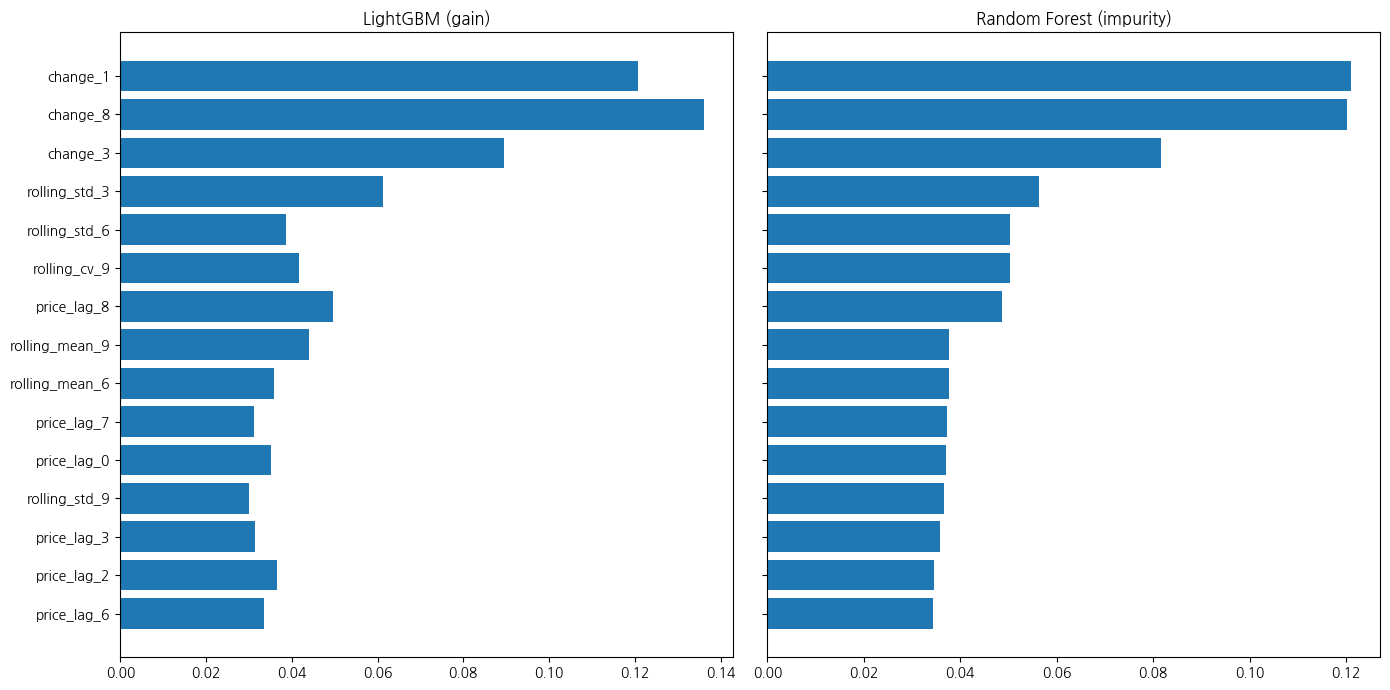


[시장 세트 LightGBM 중요도 상위 15 (h=1)]


,0
change_1,0.1080
change_3,0.1044
도매가격,0.0930
도매거래량,0.0769
change_8,0.0704
산지거래량,0.0575
rolling_std_3,0.0558
산지가격,0.0525
price_lag_0,0.0456
rolling_std_6,0.0402


In [51]:
import matplotlib.pyplot as plt
try:
    plt.rcParams["font.family"] = "NanumGothic"   # Colab: fonts-nanum 설치 후 사용 가능
except Exception:
    pass
plt.rcParams["axes.unicode_minus"] = False

imp_rows = []
for h in HORIZONS:
    y_full = log_ratio_target(model_df, h)
    lgb_m = make_model("LightGBM").fit(model_df[PRICE_FEATURES], y_full)
    rf_m = make_model("RandomForest").fit(model_df[PRICE_FEATURES], y_full)
    g_gain = lgb_m.booster_.feature_importance("gain")
    imp_rows.append(pd.DataFrame({
        "horizon": h, "feature": PRICE_FEATURES,
        "LightGBM_gain": g_gain / g_gain.sum(),
        "RF_impurity": rf_m.feature_importances_,
    }))
imp_df = pd.concat(imp_rows, ignore_index=True)

imp_mean = (imp_df.groupby("feature")[["LightGBM_gain", "RF_impurity"]].mean()
            .sort_values("RF_impurity", ascending=False))
print("[가격 피처 중요도 평균 (h=1~3)]")
display(imp_mean.round(4))

top = imp_mean.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
axes[0].barh(top.index, top["LightGBM_gain"]); axes[0].set_title("LightGBM (gain)")
axes[1].barh(top.index, top["RF_impurity"]);   axes[1].set_title("Random Forest (impurity)")
plt.tight_layout(); plt.show()

# 시장 변수 중요도 (LightGBM, h=1)
y_mk = log_ratio_target(market_model_df, 1)
lgb_mk = make_model("LightGBM").fit(market_model_df[MARKET_FEATURES], y_mk)
mk_imp = pd.Series(lgb_mk.booster_.feature_importance("gain"), index=MARKET_FEATURES)
print("\n[시장 세트 LightGBM 중요도 상위 15 (h=1)]")
display((mk_imp / mk_imp.sum()).sort_values(ascending=False).head(15).round(4))


## 5. 하이퍼파라미터 튜닝


In [52]:
RUN_TUNING = True

TUNE_GRID = {
    "RandomForest": [dict(min_samples_leaf=m, max_features=f) for m in [1, 3, 5] for f in [0.5, 1.0]],
    "LightGBM": [dict(num_leaves=n, n_estimators=e) for n in [7, 15] for e in [200, 400]],
    "CatBoost": [dict(depth=d, iterations=e) for d in [3, 4, 6] for e in [200, 400]],
}

if RUN_TUNING:
    tune_rows = []
    for name, grid in TUNE_GRID.items():
        for params in grid:
            res = walk_forward(model_df, PRICE_FEATURES, "tune",
                               model_names=[name], params={name: params})
            res["ape"] = (res["pred"] - res["y"]).abs() / res["y"] * 100
            tune_rows.append({"model": name, **params, "MAPE": res["ape"].mean()})
    tune_table = pd.DataFrame(tune_rows).sort_values(["model", "MAPE"])
    print("[튜닝 결과: 전체 예측 시점 평균 MAPE]")
    display(tune_table.round(3))
else:
    print("튜닝 생략 (RUN_TUNING = False)")


[튜닝 결과: 전체 예측 시점 평균 MAPE]


,model,min_samples_leaf,max_features,MAPE,num_leaves,n_estimators,depth,iterations
10,CatBoost,NaN,NaN,12.311,NaN,NaN,3.0,200.0
12,CatBoost,NaN,NaN,12.354,NaN,NaN,4.0,200.0
14,CatBoost,NaN,NaN,12.455,NaN,NaN,6.0,200.0
11,CatBoost,NaN,NaN,12.658,NaN,NaN,3.0,400.0
13,CatBoost,NaN,NaN,12.692,NaN,NaN,4.0,400.0
15,CatBoost,NaN,NaN,12.796,NaN,NaN,6.0,400.0
6,LightGBM,NaN,NaN,12.961,7.0,200.0,NaN,NaN
8,LightGBM,NaN,NaN,13.328,15.0,200.0,NaN,NaN
7,LightGBM,NaN,NaN,13.521,7.0,400.0,NaN,NaN
9,LightGBM,NaN,NaN,13.880,15.0,400.0,NaN,NaN


## 6. 평가 데이터(TEST) 전처리

- `TEST_xx.csv`: T-8~T 9개 시점 × 품목·품종 조합. 학습 때와 같은 필터·사과 통합 규칙을 적용.
- 가격 피처는 학습 때와 같은 식으로 계산(`price_lag_0`=T, `price_lag_k`=T-k).
- 시장 변수는 T 시점 행만 씀.

In [53]:
def load_test_price(k):
    """TEST_xx.csv → 품목별 가격 시계열 (열 0~8 = T~T-8)"""
    t = pd.read_csv(f"{folder}/TEST_{k:02d}.csv")
    for col in ["품목명", "품종명", "거래단위", "등급"]:
        t[col] = t[col].astype(str).str.strip()

    mask = pd.Series(False, index=t.index)
    for item, variety, unit, grade in targets:
        if item == "사과":
            continue
        mask |= ((t["품목명"] == item) & (t["품종명"] == variety) &
                 (t["거래단위"] == unit) & (t["등급"] == grade))

    apple_mask = ((t["품목명"] == "사과") & (t["품종명"].isin(["홍로", "후지"])) &
                  (t["거래단위"] == "10 개") & (t["등급"] == "상품"))

    tp = t[mask | apple_mask].copy()
    tp["lag"] = tp["시점"].map(lambda s: 0 if s == "T" else int(s[2:-1]))
    assert not tp.duplicated(["품목명", "lag"]).any(), f"TEST_{k:02d}: 품목·시점 중복"

    L = tp.pivot(index="품목명", columns="lag", values="평균가격(원)")
    assert L.shape == (10, 9), f"TEST_{k:02d}: 기대 shape (10, 9), 실제 {L.shape}"
    return L

def load_test_market(k):
    """TEST 산지공판장·전국도매 → T 시점 품목별 시장 변수"""
    o = pd.read_csv(f"{folder}/TEST_산지공판장_{k:02d}.csv")
    w = pd.read_csv(f"{folder}/TEST_전국도매_{k:02d}.csv")

    o_agg = aggregate_market(o, "공판장명", "*전국농협공판장")
    w_agg = aggregate_market(w, "시장명", "*전국도매시장")

    o_agg = (o_agg[o_agg["시점"] == "T"]
             .rename(columns={"거래량": "산지거래량", "시장평균가격": "산지가격"})
             [["품목명", "산지거래량", "산지가격"]])
    w_agg = (w_agg[w_agg["시점"] == "T"]
             .rename(columns={"거래량": "도매거래량", "시장평균가격": "도매가격"})
             [["품목명", "도매거래량", "도매가격"]])
    return o_agg.merge(w_agg, on="품목명", how="outer")

def price_features_from_lags(L):
    """학습 전처리(feature_df)와 같은 가격 피처 계산식"""
    F = pd.DataFrame(index=L.index)
    for i in range(9):
        F[f"price_lag_{i}"] = L[i]
    for w in [3, 6, 9]:
        win = L[list(range(w))]
        F[f"rolling_mean_{w}"] = win.mean(axis=1)
        F[f"rolling_std_{w}"] = win.std(axis=1, ddof=1)
    F["rolling_cv_9"] = F["rolling_std_9"] / F["rolling_mean_9"] * 100
    F["change_1"] = L[0] / L[1] - 1
    F["change_3"] = L[0] / L[3] - 1
    F["change_8"] = L[0] / L[8] - 1
    return F

def build_test_features(k):
    L = load_test_price(k)
    F = price_features_from_lags(L).reset_index()   # 품목명 컬럼 복원

    dummies = (pd.get_dummies(F["품목명"], prefix="item", dtype=int)
               .reindex(columns=item_cols, fill_value=0))
    F = pd.concat([F, dummies], axis=1)

    F = F.merge(load_test_market(k), on="품목명", how="left")
    F["test_k"] = k
    return F


In [54]:
test_all = pd.concat([build_test_features(k) for k in range(25)], ignore_index=True)

print("평가 데이터 행 수:", len(test_all), "(기대: 25 × 10 = 250)")
assert len(test_all) == 250
assert test_all[PRICE_FEATURES].notna().all().all()
display(test_all[["test_k", "품목명", "price_lag_0", "rolling_cv_9", "산지가격", "도매가격"]].head(12))


평가 데이터 행 수: 250 (기대: 25 × 10 = 250)


,test_k,품목명,price_lag_0,rolling_cv_9,산지가격,도매가격
0,0,감자,37901.375000,4.924426,1416.267404,1531.196399
1,0,건고추,673700.000000,8.472955,NaN,NaN
2,0,깐마늘(국산),168000.000000,2.252526,3428.432723,6644.143716
3,0,대파,2097.375000,11.561231,2015.782144,1839.601739
4,0,무,34129.250000,21.033539,1585.864425,1549.162131
5,0,배,30762.000000,9.596455,1581.449684,1729.411355
6,0,배추,17092.500000,24.844151,1547.895217,1250.546293
7,0,사과,23823.000000,10.365948,2874.274807,2928.660653
8,0,상추,1213.000000,20.601176,3741.437459,2346.197605
9,0,양파,1513.375000,6.759588,1379.779728,1260.490579


## 7. 최종 예측 및 제출 파일

- 호라이즌별로 선택된 설정을 **전체 학습 데이터로 다시 학습**한 뒤 TEST에 적용.
- 시장 모델이 가능한 품목(학습 데이터에 있고 TEST 시장 값이 채워진 행)은 시장 모델을, 나머지는 가격 모델을 씀.
- 참고용으로 모든 세트·모델의 TEST 예측도 `test_predictions_by_model.csv`로 저장합니다(앙상블 담당용).

In [55]:
TRAIN_SETS = {
    "price_all":         (model_df, PRICE_FEATURES),
    "price_mkt_rows":    (market_model_df, PRICE_FEATURES),
    "price+market_rows": (market_model_df, MARKET_FEATURES),
}

def predict_config(set_name, model_name, h, test_df):
    train_df, feats = TRAIN_SETS[set_name]
    ok = test_df[feats].notna().all(axis=1)
    if set_name != "price_all":
        ok &= test_df["품목명"].isin(COVERED_ITEMS)

    pred = pd.Series(np.nan, index=test_df.index)
    if ok.any():
        ratio = predict_ratio(model_name, train_df[feats],
                              log_ratio_target(train_df, h),
                              test_df.loc[ok, feats])
        pred.loc[ok] = test_df.loc[ok, "price_lag_0"].values * np.exp(ratio)
    return pred

by_model_parts = []
for set_name in TRAIN_SETS:
    for model_name in MODEL_NAMES:
        for h in HORIZONS:
            p = predict_config(set_name, model_name, h, test_all)
            tmp = test_all[["test_k", "품목명"]].copy()
            tmp["set"], tmp["model"], tmp["horizon"] = set_name, model_name, h
            tmp["pred"] = p.values
            by_model_parts.append(tmp)
by_model = pd.concat(by_model_parts, ignore_index=True)
by_model.to_csv(f"{folder}/test_predictions_by_model.csv", index=False, encoding="utf-8-sig")
print("모델별 TEST 예측 저장:", by_model.shape)

# 최종 제출: 호라이즌별 선택 설정
long_parts = []
for h in HORIZONS:
    pred_px = predict_config("price_all", CONFIG[h]["price"][1], h, test_all)
    pred_mk = predict_config(CONFIG[h]["market"][0], CONFIG[h]["market"][1], h, test_all)
    final = pred_mk.where(pred_mk.notna(), pred_px)
    assert final.notna().all(), f"h={h}: 예측 결측 존재"

    tmp = test_all[["test_k", "품목명"]].copy()
    tmp["시점"] = "TEST_" + tmp["test_k"].map("{:02d}".format) + f"+{h}순"
    tmp["pred"] = final.values
    tmp["source"] = np.where(pred_mk.notna(), "market", "price")
    long_parts.append(tmp)

long_pred = pd.concat(long_parts, ignore_index=True)
print("예측 출처 분포:")
print(long_pred.groupby(["품목명", "source"]).size().unstack(fill_value=0))

wide = long_pred.pivot(index="시점", columns="품목명", values="pred")
sample = pd.read_csv(f"{folder}/sample_submission.csv")
submission = wide.reindex(sample["시점"]).reset_index()
submission = submission[sample.columns]

assert submission.shape == sample.shape
assert submission.notna().all().all()
assert list(submission.columns) == list(sample.columns)

submission.to_csv(f"{folder}/submission_model.csv", index=False, encoding="utf-8")
print("저장 완료:", f"{folder}/submission_model.csv", submission.shape)
display(submission.head())


모델별 TEST 예측 저장: (11250, 6)
예측 출처 분포:
source   market  price
품목명                   
감자           75      0
건고추           0     75
깐마늘(국산)      75      0
대파           75      0
무            75      0
배            75      0
배추           75      0
사과           75      0
상추           75      0
양파           75      0
저장 완료: /content/drive/MyDrive/[ESAA] OB 1조/프로젝트3/submission_model.csv (75, 11)


품목명,시점,감자,건고추,깐마늘(국산),대파,무,배추,사과,상추,양파,배
0,TEST_00+1순,37905.029527,679366.365748,167146.998892,2113.323047,33734.717153,14488.163523,23452.063131,1138.160202,1522.571954,28783.071867
1,TEST_00+2순,38379.817143,673700.000000,167461.327662,2128.414028,31802.104656,14401.236443,23121.091725,1097.544323,1514.780345,27444.084962
2,TEST_00+3순,38634.184168,659774.612551,166703.779207,2114.350797,28005.245741,13813.898386,22424.549063,1076.422011,1505.045745,26735.475875
3,TEST_01+1순,40941.897228,640724.573854,166875.689746,1866.390114,12492.309283,5733.731979,22610.131156,999.319159,1467.031016,24734.197172
4,TEST_01+2순,41500.939747,650325.000000,167424.881034,1841.796101,11821.951714,5507.230812,21826.231723,993.740042,1420.279612,24145.910420


### 8. 최종 모델링 검증 결과 및 요약

#### 8.1 세트별 / 모델별 / 예측 시점별 MAPE(%) 성능 비교
- **가격 기반 전체 데이터셋 (`price_all`) 성능**:
  - 단기 예측인 h=1과 장기 예측인 h=3 시점에서는 CatBoost 모델이 각각 7.93%, 16.45%의 MAPE를 기록하며 Baseline(7.94%, 16.60%)을 포함한 타 모델 대비 가장 우수한 예측력을 보임.
  - 중간 시점인 h=2에서는 Baseline(현재가 유지) 모델이 12.51%로 미세하게 가장 좋은 성능을 보임.

- **시장 변수 포함 데이터셋 (`price+market_rows`) 성능**:
  - 시장 보조 변수(산지/도매 거래량 및 가격)를 통합하여 학습한 결과, 모든 예측 시차(**h=1: 8.47%**, **h=2: 13.39%**, **h=3: 17.54%**)에서 **CatBoost** 모델이 가장 낮은 MAPE를 기록하여 최종 시장 변수 기반 예측 모델로 채택.

- **최종 앙상블 및 적용 전략**:
  - 시장 데이터가 유효하게 존재하는 9개 품목('감자', '깐마늘(국산)', '대파', '무', '배', '배추', '사과', '상추', '양파')에 대해서는 **CatBoost 기반의 시장 모델**을 적용.
  - 시장 변수가 존재하지 않는 '건고추' 품목 및 보조 데이터 결측 시점에는 예측 시점별 최적 설정(h=1,3: CatBoost, h=2: Baseline)의 **가격 모델**을 상호 보완적으로 적용하여 예측 안정성을 극대화.

#### 8.2 하이퍼파라미터 튜닝 결과 요약
- **그리드 탐색(Grid Search) 기반 최적화 결과**:
  - Random Forest, LightGBM, CatBoost를 대상으로 연도별 Walk-forward 교차 검증을 수행하여 하이퍼파라미터를 튜닝하였습니다.
  - 전체 예측 시점(h=1~3) 평균 MAPE 기준으로 **CatBoost (depth=3, iterations=200)** 설정이 약 **12.31%**로 전체 후보군 중 가장 뛰어난 일반화 성능을 달성.
  - 뒤를 이어 **Random Forest (min_samples_leaf=5, max_features=0.5)**가 약 **12.63%**, **LightGBM (num_leaves=7, n_estimators=200)**이 약 **12.96%**의 평균 MAPE를 보임.

# 검증 및 앙상블
모델링 단계에서 저장한 validation 예측값으로 앙상블 방법을 정하고, 같은 방법을 TEST 예측값에 적용해 최종 제출 파일을 만든다.

In [59]:
import pandas as pd
import numpy as np

path = '/content/drive/MyDrive/[ESAA] OB 1조/프로젝트3/'
val = pd.read_csv(path + 'validation_predictions.csv')
test = pd.read_csv(path + 'test_predictions_by_model.csv')
sub = pd.read_csv(path + 'submission_model.csv')

print(val.shape, test.shape, sub.shape)
val.head()

(44100, 9) (11250, 6) (75, 11)


,set,fold,horizon,model,품목명,y,pred,ae,ape
0,price_all,2019,1,Baseline,감자,39410.625000,42425.857143,3015.232143,7.650810
1,price_all,2019,1,Baseline,감자,40487.000000,39410.625000,1076.375000,2.658569
2,price_all,2019,1,Baseline,감자,42759.800000,40487.000000,2272.800000,5.315273
3,price_all,2019,1,Baseline,감자,42351.444444,42759.800000,408.355556,0.964207
4,price_all,2019,1,Baseline,감자,41386.428571,42351.444444,965.015873,2.331721


## 1. validation 데이터 정리
- 현재 제출과 같은 기준으로 맞춘다: 9개 품목은 `price+market_rows`, 건고추는 `price_all`
- 모델별 예측값을 옆으로 펼쳐서(한 행 = 한 예측 시점) 비교하기 쉽게 만든다

In [60]:
# 같은 (set, fold, horizon, 모델, 품목) 안에서 몇 번째 행인지 번호 붙이기
val['row'] = val.groupby(['set', 'fold', 'horizon', 'model', '품목명']).cumcount()

# 모델별 예측값을 열로 펼치기
wide = val.pivot_table(index=['set', 'fold', 'horizon', '품목명', 'row', 'y'],
                       columns='model', values='pred').reset_index()

# 9개 품목은 시장변수 세트, 건고추는 가격 세트
cond1 = (wide['set'] == 'price+market_rows') & (wide['품목명'] != '건고추')
cond2 = (wide['set'] == 'price_all') & (wide['품목명'] == '건고추')
df = wide[cond1 | cond2].copy()

# 현재 제출 방식 (건고추 h=2만 Baseline, 나머지는 CatBoost)
df['현재제출'] = df['CatBoost']
df.loc[(df['품목명'] == '건고추') & (df['horizon'] == 2), '현재제출'] = df['Baseline']

print(df.shape)
df.head()

(3150, 12)


model,set,fold,horizon,품목명,row,y,Baseline,CatBoost,LightGBM,RandomForest,XGBoost,현재제출
0,price+market_rows,2019,1,감자,0,39410.625000,42425.857143,42492.506666,41843.756980,42490.155335,42454.209803,42492.506666
1,price+market_rows,2019,1,감자,1,40487.000000,39410.625000,38672.689852,40437.428841,40106.577273,41130.411403,38672.689852
2,price+market_rows,2019,1,감자,2,42759.800000,40487.000000,40678.480677,40348.312422,40777.291250,40306.194823,40678.480677
3,price+market_rows,2019,1,감자,3,42351.444444,42759.800000,43099.513999,43006.774794,43070.380924,42812.710653,43099.513999
4,price+market_rows,2019,1,감자,4,41386.428571,42351.444444,42465.386557,41903.414803,42395.297440,41799.870494,42465.386557


In [61]:
# 평가 함수 (MAPE, %)
def mape(y, pred):
    return (abs(y - pred) / abs(y)).mean() * 100

## 2. 앙상블 A: Baseline + α × CatBoost 변화율
- 예측 = Baseline × (CatBoost / Baseline)^α
- α=0이면 Baseline 그대로, α=1이면 CatBoost 그대로

In [62]:
alpha_list = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

for h in [1, 2, 3]:
    d = df[df['horizon'] == h]
    best_a = 0
    best_score = 999
    for a in alpha_list:
        pred = d['Baseline'] * (d['CatBoost'] / d['Baseline']) ** a
        score = mape(d['y'], pred)
        if score < best_score:
            best_score = score
            best_a = a
    print(f'h={h}  best alpha={best_a}  MAPE={best_score:.2f}')

h=1  best alpha=0.6  MAPE=7.78
h=2  best alpha=0.5  MAPE=12.22
h=3  best alpha=0.5  MAPE=16.01


## 3. 앙상블 B: CatBoost, RF, Baseline 가중 평균
0.1 단위로 가중치 조합을 모두 시도한다 (세 가중치 합 = 1)

In [63]:
best_weights = {}

for h in [1, 2, 3]:
    d = df[df['horizon'] == h]
    best_score = 999
    for w_cat in np.arange(0, 1.01, 0.1):
        for w_rf in np.arange(0, 1.01 - w_cat, 0.1):
            w_base = 1 - w_cat - w_rf
            pred = w_cat * d['CatBoost'] + w_rf * d['RandomForest'] + w_base * d['Baseline']
            score = mape(d['y'], pred)
            if score < best_score:
                best_score = score
                best_weights[h] = (round(w_cat, 1), round(w_rf, 1), round(w_base, 1))
    print(f'h={h}  best (Cat, RF, Base)={best_weights[h]}  MAPE={best_score:.2f}')

h=1  best (Cat, RF, Base)=(np.float64(0.3), np.float64(0.3), np.float64(0.4))  MAPE=7.76
h=2  best (Cat, RF, Base)=(np.float64(0.2), np.float64(0.3), np.float64(0.5))  MAPE=12.19
h=3  best (Cat, RF, Base)=(np.float64(0.3), np.float64(0.3), np.float64(0.4))  MAPE=15.98


## 4. 앙상블 C: 세 모델 단순 평균 (가중치 튜닝 없음)

In [64]:
df['단순평균'] = (df['CatBoost'] + df['RandomForest'] + df['Baseline']) / 3

result = []
for h in [1, 2, 3]:
    d = df[df['horizon'] == h]
    result.append({
        'horizon': h,
        'Baseline': mape(d['y'], d['Baseline']),
        'CatBoost': mape(d['y'], d['CatBoost']),
        '현재제출': mape(d['y'], d['현재제출']),
        '단순평균': mape(d['y'], d['단순평균']),
    })
pd.DataFrame(result).round(2)

,horizon,Baseline,CatBoost,현재제출,단순평균
0,1,7.94,7.85,7.85,7.76
1,2,12.51,12.46,12.40,12.20
2,3,16.60,16.36,16.36,16.01


## 5. 폴드별로 결과가 일관되는지 확인
가중치를 고를 때 쓰지 않은 연도로 평가해야 공정하다.
→ 두 해로 가중치를 고르고, 남은 한 해로 점수를 매긴다 (3번 반복)

In [65]:
rows = []
for h in [1, 2, 3]:
    d = df[df['horizon'] == h]
    for f in [2019, 2020, 2021]:
        tr = d[d['fold'] != f]   # 가중치 고르는 용도
        te = d[d['fold'] == f]   # 평가 용도

        # 남은 두 해로 가중치 고르기
        best_score = 999
        best_w = None
        for w_cat in np.arange(0, 1.01, 0.1):
            for w_rf in np.arange(0, 1.01 - w_cat, 0.1):
                w_base = 1 - w_cat - w_rf
                pred = w_cat * tr['CatBoost'] + w_rf * tr['RandomForest'] + w_base * tr['Baseline']
                score = mape(tr['y'], pred)
                if score < best_score:
                    best_score = score
                    best_w = (w_cat, w_rf, w_base)

        tuned = best_w[0] * te['CatBoost'] + best_w[1] * te['RandomForest'] + best_w[2] * te['Baseline']
        rows.append({
            'horizon': h, 'fold': f,
            'Baseline': mape(te['y'], te['Baseline']),
            '현재제출': mape(te['y'], te['현재제출']),
            '가중평균(튜닝)': mape(te['y'], tuned),
            '단순평균': mape(te['y'], te['단순평균']),
        })

fold_result = pd.DataFrame(rows).round(2)
fold_result

,horizon,fold,Baseline,현재제출,가중평균(튜닝),단순평균
0,1,2019,6.78,6.84,6.68,6.65
1,1,2020,8.32,8.21,8.14,8.14
2,1,2021,8.81,8.56,8.58,8.56
3,2,2019,10.46,11.17,10.71,10.51
4,2,2020,13.32,12.72,12.93,12.81
5,2,2021,13.88,13.38,13.43,13.38
6,3,2019,13.65,14.72,14.10,13.81
7,3,2020,18.25,17.05,17.43,17.13
8,3,2021,18.01,17.39,17.23,17.18


In [66]:
# 단순평균이 현재 제출보다 좋은 경우가 몇 번인지
print((fold_result['단순평균'] <= fold_result['현재제출']).sum(), '/ 9')

7 / 9


## 6. 최종 제출 파일 만들기
단순평균 방식(CatBoost, RF, Baseline 1/3씩)을 TEST 예측값에 그대로 적용한다.

In [67]:
final = sub.copy()

for i in range(len(final)):
    name = final.loc[i, '시점']        # 예: TEST_00+1순
    k = int(name[5:7])                 # TEST 번호
    h = int(name[8])                   # 몇 순 뒤인지

    for item in final.columns[1:]:
        if item == '건고추':
            s = 'price_all'
        else:
            s = 'price+market_rows'

        preds = []
        for m in ['CatBoost', 'RandomForest', 'Baseline']:
            r = test[(test['set'] == s) & (test['model'] == m) & (test['품목명'] == item)
                     & (test['horizon'] == h) & (test['test_k'] == k)]
            preds.append(r['pred'].values[0])

        final.loc[i, item] = sum(preds) / 3

final.to_csv('submission_ensemble.csv', index=False)
print(final.shape)
final.head()

(75, 11)


,시점,감자,건고추,깐마늘(국산),대파,무,배추,사과,상추,양파,배
0,TEST_00+1순,37963.205009,676260.909198,167751.239095,2058.796958,33453.028580,15173.738521,23694.498199,1137.590573,1510.786528,29713.634987
1,TEST_00+2순,38398.793936,672470.417780,168451.322581,2073.976137,32086.518907,14653.305450,23182.356838,1100.197708,1507.862107,28647.726498
2,TEST_00+3순,38896.987980,672523.942159,168727.558619,2057.424966,29269.652757,14178.504975,22918.843185,1097.165372,1505.583701,28281.916604
3,TEST_01+1순,41078.278735,644220.267981,167700.480098,1811.585751,12985.682794,5782.674426,22674.625986,1011.762153,1471.454810,24928.419260
4,TEST_01+2순,41658.003663,640104.734996,168480.160194,1785.958295,12349.121999,5747.251633,22413.139430,993.805546,1448.188144,24522.800103


In [68]:
# 확인: 결측치 없는지, 현재 제출과 얼마나 다른지
print('결측치:', final.isnull().sum().sum())
diff = (final.iloc[:, 1:] / sub.iloc[:, 1:] - 1) * 100
print('현재 제출 대비 평균 변화(%)')
print(diff.abs().mean().round(2))

결측치: 0
현재 제출 대비 평균 변화(%)
감자         1.53
건고추        0.75
깐마늘(국산)    0.60
대파         1.74
무          2.65
배추         2.81
사과         1.08
상추         1.55
양파         2.26
배          1.24
dtype: float64


In [69]:
df['Cat+Base'] = (df['CatBoost'] + df['Baseline']) / 2
df['Cat+RF'] = (df['CatBoost'] + df['RandomForest']) / 2
df['5개평균'] = (df['CatBoost'] + df['RandomForest'] + df['Baseline']
                + df['LightGBM'] + df['XGBoost']) / 5

combo = []
for h in [1, 2, 3]:
    d = df[df['horizon'] == h]
    combo.append({
        'horizon': h,
        '현재제출': mape(d['y'], d['현재제출']),
        '단순평균(3개)': mape(d['y'], d['단순평균']),
        'Cat+Base': mape(d['y'], d['Cat+Base']),
        'Cat+RF': mape(d['y'], d['Cat+RF']),
        '5개평균': mape(d['y'], d['5개평균']),
    })
pd.DataFrame(combo).round(2)

,horizon,현재제출,단순평균(3개),Cat+Base,Cat+RF,5개평균
0,1,7.85,7.76,7.78,7.83,7.88
1,2,12.40,12.20,12.23,12.41,12.40
2,3,16.36,16.01,16.05,16.28,16.27


In [70]:
item_result = []
for item in df['품목명'].unique():
    d = df[df['품목명'] == item]
    item_result.append({
        '품목': item,
        'Baseline': mape(d['y'], d['Baseline']),
        '현재제출': mape(d['y'], d['현재제출']),
        '단순평균': mape(d['y'], d['단순평균']),
    })
pd.DataFrame(item_result).round(2)

,품목,Baseline,현재제출,단순평균
0,감자,15.30,14.23,14.15
1,깐마늘(국산),2.95,3.96,3.43
2,대파,18.77,19.22,18.52
3,무,18.01,18.44,18.11
4,배,5.03,5.35,5.05
5,배추,24.18,22.18,22.59
6,사과,4.85,5.03,4.80
7,상추,16.72,15.90,15.79
8,양파,14.38,13.92,13.69
9,건고추,3.34,3.78,3.75


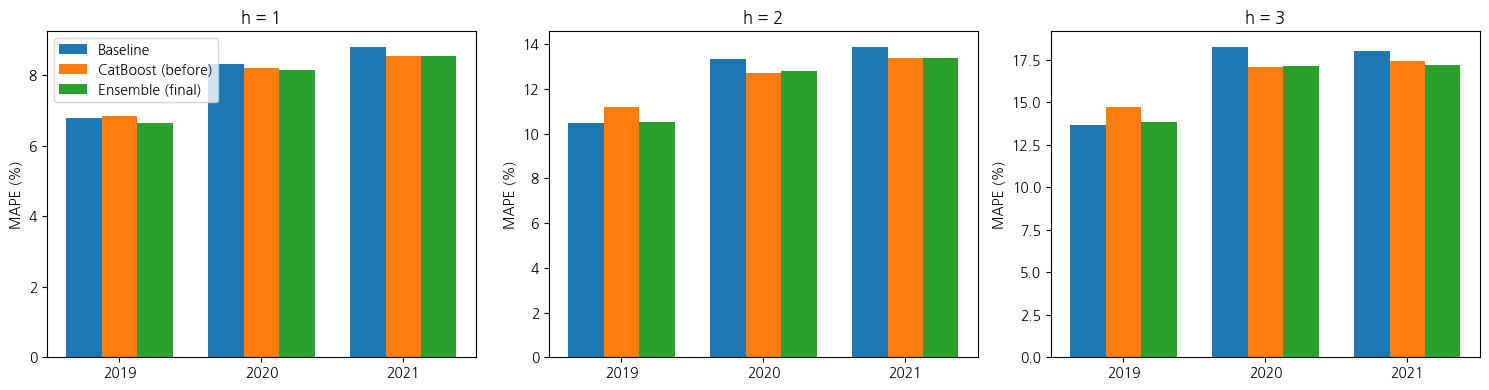

In [71]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, h in enumerate([1, 2, 3]):
    d = fold_result[fold_result['horizon'] == h]
    x = np.arange(3)
    axes[i].bar(x - 0.25, d['Baseline'], width=0.25, label='Baseline')
    axes[i].bar(x, d['현재제출'], width=0.25, label='CatBoost (before)')
    axes[i].bar(x + 0.25, d['단순평균'], width=0.25, label='Ensemble (final)')
    axes[i].set_xticks(x)
    axes[i].set_xticklabels([2019, 2020, 2021])
    axes[i].set_title(f'h = {h}')
    axes[i].set_ylabel('MAPE (%)')

axes[0].legend()
plt.tight_layout()
plt.show()

## 결론
- CatBoost, RandomForest, Baseline 세 모델을 1/3씩 단순 평균한 것을 최종 앙상블로 선택
- validation MAPE: 7.85 / 12.40 / 16.36 → 7.76 / 12.20 / 16.01 (1·2·3순)
- 가중치 튜닝과 α 방식도 시도했지만, 단순평균과 차이가 거의 없고 튜닝에 안 쓴 연도에서 더 불안정해서 제외
- 연도별(2019~2021) 9번 비교 중 7번 현재 제출과 같거나 더 좋음
- LightGBM, XGBoost를 추가하면 성능이 떨어져 제외
- 품목별 모델 선택은 학습 데이터가 적어 과적합 위험 때문에 보류